In [24]:
# copy code (Eda_clustering)
import datetime as dt
import numpy as np
import pandas as pd

import requests
import re

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import keras
import tensorflow as tf
from keras import layers
from keras.layers import RepeatVector
from keras.callbacks import ModelCheckpoint, EarlyStopping, TensorBoard
from keras.layers import LSTM, Dropout, Dense
from keras.models import Sequential, Model, load_model
from keras.layers import Input, Dense, Activation, Flatten, Dropout
from keras.layers import SimpleRNN, GRU
from keras.utils import to_categorical
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Input

from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest

import pickle 
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, RepeatVector, TimeDistributed, Dense

import prophet
from prophet import Prophet
from prophet.diagnostics import cross_validation
from prophet.diagnostics import performance_metrics
from prophet.plot import add_changepoints_to_plot
from prophet.plot import plot_cross_validation_metric
from prophet.plot import plot_plotly
from prophet.serialize import model_to_json
import plotly.graph_objs as go

# Pickle Save object
def save_obj(obj, filename):
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

# Pickle Read Object
def read_obj(filename):
    
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'rb') as inp:  # Reads File
        return pickle.load(inp)

/opt/anaconda3/envs/research/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [34]:
### Visualization 2020 to 2023

df = pd.read_csv("./CSV data/GT/GT_final.csv")
df.head()

start_date = '2020-01-01 00:00:00'
num_rows = len(df)
date_range = pd.date_range(start=start_date, periods=num_rows, freq='H')

df['date'] = date_range
df.to_csv("./CSV data/GT/GT_final_date.csv", index = False)


/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_97266/832067052.py:8: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  date_range = pd.date_range(start=start_date, periods=num_rows, freq='H')


In [35]:
df = pd.read_csv("./CSV data/GT/GT_final_date.csv")

In [36]:
### spike 처리 

date = df['date']
df = df[df.iloc[:, :-1] < 300]
df = df[df.iloc[:, :-1] > -300]
df['date'] = date

### Neural ODE

In [77]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

# Sinusoidal Time Embedding
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, embedding_dim):
        super(SinusoidalTimeEmbedding, self).__init__()
        # Automatically make the embedding_dim even if it's odd
        if embedding_dim % 2 != 0:
            embedding_dim += 1  # Add 1 to make it even
        self.embedding_dim = embedding_dim

    def forward(self, time_steps):
        device = time_steps.device
        batch_size, seq_len = time_steps.size()
        pe = torch.zeros(batch_size, seq_len, self.embedding_dim).to(device)

        position = time_steps.unsqueeze(-1)  # [batch_size, seq_len, 1]
        div_term = torch.exp(torch.arange(0, self.embedding_dim, 2, dtype=torch.float32).to(device) *
                             -(np.log(10000.0) / self.embedding_dim))  # [embedding_dim // 2]
        
        # Ensure the shape alignment for both sin and cos computations
        pe[..., 0::2] = torch.sin(position * div_term)  # Sine part
        pe[..., 1::2] = torch.cos(position * div_term)  # Cosine part

        return pe

class ODEF(nn.Module):
    def __init__(self, hidden_dim):
        super(ODEF, self).__init__()
        self.linear1 = nn.Linear(hidden_dim, hidden_dim*2)
        self.bn1 = nn.BatchNorm1d(hidden_dim*2)
        self.linear2 = nn.Linear(hidden_dim*2, hidden_dim*2)
        self.bn2 = nn.BatchNorm1d(hidden_dim*2)
        self.linear3 = nn.Linear(hidden_dim*2, hidden_dim)
        self.dropout = nn.Dropout(0.2)
        
    def forward(self, t, h):
        batch_size = h.size(0)
        h = self.linear1(h)
        h = self.bn1(h.view(-1, h.size(-1))).view(batch_size, -1)
        h = F.relu(h)
        h = self.dropout(h)
        h = self.linear2(h)
        h = self.bn2(h.view(-1, h.size(-1))).view(batch_size, -1)
        h = F.relu(h)
        h = self.dropout(h)
        return self.linear3(h)
    
# GRU-style ODE-RNN Encoder
class ODERNNEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(ODERNNEncoder, self).__init__()
        self.hidden_dim = hidden_dim
        self.odefunc = ODEF(hidden_dim)
        self.gru = nn.GRUCell(input_dim, hidden_dim)
        self.h0 = nn.Parameter(torch.zeros(hidden_dim))

    def forward(self, x, time_steps):
        batch_size, seq_len, _ = x.size()
        h = self.h0.unsqueeze(0).repeat(batch_size, 1)

        outputs = []
        for i in range(seq_len):
            if i > 0:
                dt = time_steps[:, i] - time_steps[:, i - 1]
                h = h + self.odefunc(None, h) * dt.unsqueeze(1)
            h = self.gru(x[:, i], h)
            outputs.append(h.unsqueeze(1))

        return torch.cat(outputs, dim=1)

# ODE-based Decoder
class ODEDecoder(nn.Module):
    def __init__(self, hidden_dim, output_dim):
        super(ODEDecoder, self).__init__()
        self.odefunc = ODEF(hidden_dim)
        self.linear = nn.Linear(hidden_dim, output_dim)

    def forward(self, z0, time_steps):
        batch_size, seq_len = time_steps.size()
        h = z0
        outputs = []
        for i in range(seq_len):
            if i > 0:
                # Ensure time_steps are correctly reshaped for element-wise operations
                dt = time_steps[:, i] - time_steps[:, i - 1]
                dt = dt.unsqueeze(1)  # This ensures dt has the shape [batch_size, 1]
                h = h + self.odefunc(None, h) * dt  # Ensure the dimensions of h and dt align

            outputs.append(self.linear(h).unsqueeze(1))
        return torch.cat(outputs, dim=1)


# Transformer with Causal Masking
class TimeSeriesTransformer(nn.Module):
    def __init__(self, input_dim, num_heads, num_layers=2, hidden_dim=128):
        super(TimeSeriesTransformer, self).__init__()
        self.fc_embed = nn.Linear(input_dim, hidden_dim)
        encoder_layer = nn.TransformerEncoderLayer(d_model=hidden_dim, nhead=num_heads, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(hidden_dim, 1)  

    def generate_causal_mask(self, size):
        # (seq_len, seq_len)
        return torch.triu(torch.ones(size, size), diagonal=1).bool()

    def forward(self, src):
        batch_size, seq_len, _ = src.size()
        src = self.fc_embed(src)
        mask = self.generate_causal_mask(seq_len).to(src.device)
        out = self.transformer(src, mask=mask)
        return self.fc_out(out).squeeze(-1)  

class AnomalyDetector(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_heads=4):
        super(AnomalyDetector, self).__init__()
        # 기존 모듈 활용
        self.encoder = ODERNNEncoder(input_dim=input_dim, hidden_dim=hidden_dim)
        self.decoder = ODEDecoder(hidden_dim=hidden_dim, output_dim=input_dim)
        self.time_embedding = SinusoidalTimeEmbedding(embedding_dim=input_dim)
        self.transformer = TimeSeriesTransformer(input_dim=input_dim, num_heads=num_heads)
        
        # 추가 레이어
        self.anomaly_fc = nn.Linear(hidden_dim, hidden_dim//2)
        self.anomaly_out = nn.Linear(hidden_dim//2, 1)
        
        # 성능 향상을 위한 추가 컴포넌트
        self.conv_small = nn.Conv1d(input_dim, hidden_dim//2, kernel_size=3, padding=1)
        self.conv_large = nn.Conv1d(input_dim, hidden_dim//2, kernel_size=7, padding=3)
        self.fusion_layer = nn.Linear(hidden_dim*2, hidden_dim)
        self.dropout = nn.Dropout(0.2)
        
    def forward(self, x, time_steps):
        # 입력 차원 처리
        if len(x.shape) == 2:
            x = x.unsqueeze(1)  # [batch_size, features] -> [batch_size, 1, features]
        
        # time_steps 형태 처리
        if time_steps.dim() == 1:
            time_steps = time_steps.unsqueeze(0).expand(x.size(0), -1)  # [seq_len] -> [batch_size, seq_len]
        
        # 인코더를 통한 시퀀스 인코딩
        encoded = self.encoder(x, time_steps)  # [batch_size, seq_len, hidden_dim]
        
        # 인코더의 마지막 hidden state 사용
        z0 = encoded[:, -1, :]  # [batch_size, hidden_dim]
        
        # 디코더를 통한 재구성
        reconstructed = self.decoder(z0, time_steps)  # [batch_size, seq_len, input_dim]
        
        # 시간 임베딩 적용
        time_embed = self.time_embedding(time_steps)  # [batch_size, seq_len, input_dim]
        
        # 차원 맞추기
        if time_embed.size(2) != reconstructed.size(2):
            time_embed = time_embed[:, :, :reconstructed.size(2)]
        
        # 재구성된 데이터에 시간 정보 추가
        reconstructed_with_time = reconstructed + time_embed
        
        # 재구성 오차 계산 (향상된 버전)
        recon_error_per_feature = torch.mean(torch.square(x - reconstructed), dim=1)
        # 특성별 중요도를 고려한 가중 재구성 오차
        feature_importance = F.softmax(torch.mean(torch.abs(x), dim=1), dim=-1)
        weighted_recon_error = torch.sum(recon_error_per_feature * feature_importance, dim=1)
        
        # 트랜스포머로 시계열 패턴 분석
        pattern_scores = self.transformer(reconstructed_with_time)
        pattern_score = torch.mean(pattern_scores, dim=1)
        
        # 컨볼루션 특징 추출
        x_permuted = x.permute(0, 2, 1)  # [batch, features, seq_len]
        conv_feat1 = F.relu(self.conv_small(x_permuted))
        conv_feat2 = F.relu(self.conv_large(x_permuted))
        
        # 특징 평균화
        conv_feat1 = torch.mean(conv_feat1, dim=2)
        conv_feat2 = torch.mean(conv_feat2, dim=2)
        conv_features = torch.cat([conv_feat1, conv_feat2], dim=1)
        
        # 시계열 변화율 특징 (안전하게 계산)
        batch_size, seq_len, feature_dim = x.size()
        if seq_len > 1:
            dx = x[:, 1:] - x[:, :-1]
            dx_mean = torch.mean(torch.abs(dx), dim=[1, 2])
            dx_max = torch.max(torch.abs(dx), dim=2)[0].mean(dim=1)
            # 정규화된 변화율 점수
            normalized_dx = torch.sigmoid((dx_max - dx_mean) * 5)
        else:
            # 시퀀스 길이가 1인 경우 대체값 사용
            normalized_dx = torch.zeros(batch_size, device=x.device)
        
        # 인코딩된 특징과 추가 특징 결합
        encoded_features = torch.mean(encoded, dim=1)
        combined_features = torch.cat([encoded_features, conv_features], dim=1)
        
        # 특징 융합
        fused_features = F.relu(self.fusion_layer(combined_features))
        fused_features = self.dropout(fused_features)
        
        # 특성 기반 이상 점수 계산
        anomaly_features = F.relu(self.anomaly_fc(fused_features))
        feature_score = self.anomaly_out(anomaly_features).squeeze(-1)
        
        # 각 점수 정규화
        normalized_recon = torch.sigmoid(weighted_recon_error * 5)
        normalized_pattern = torch.sigmoid(pattern_score)
        normalized_feature = torch.sigmoid(feature_score)
        
        # 가중 결합 (F1 향상을 위한 가중치 조정)
        anomaly_score = (0.4 * normalized_recon + 
                        0.3 * normalized_pattern + 
                        0.2 * normalized_feature + 
                        0.1 * normalized_dx)
        
        return anomaly_score

In [78]:
def train_enhanced_anomaly_detector(model, train_loader, optimizer, num_epochs, device):
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        
        for x_batch, time_steps in train_loader:
            x_batch = x_batch.to(device)
            time_steps = time_steps.to(device)
            
            # 1. 정상 데이터 처리
            encoded_normal = model.encoder(x_batch, time_steps)
            z0_normal = encoded_normal[:, -1, :]
            reconstructed_normal = model.decoder(z0_normal, time_steps)
            
            # 재구성 손실
            recon_loss = F.mse_loss(reconstructed_normal, x_batch)
            
            # 2. 인공 이상치 생성
            noise_level = min(0.1 + epoch * 0.01, 0.5)  # 점진적 노이즈 증가
            noise_mask = (torch.rand_like(x_batch[:, :, 0:1]) < 0.2).float()
            noise = torch.randn_like(x_batch) * noise_level * noise_mask
            noisy_x = x_batch + noise
            
            # 이상치 데이터 처리
            encoded_anomaly = model.encoder(noisy_x, time_steps)
            z0_anomaly = encoded_anomaly[:, -1, :]
            reconstructed_anomaly = model.decoder(z0_anomaly, time_steps)
            
            # 3. 특징 대조 손실
            normal_features = encoded_normal.mean(dim=1)
            anomaly_features = encoded_anomaly.mean(dim=1)
            contrast_loss = feature_contrastive_loss(normal_features, anomaly_features, margin=2.0)
            
            # 4. 시간적 일관성 손실
            normal_scores = model(x_batch, time_steps)
            anomaly_scores = model(noisy_x, time_steps)
            temporal_loss = temporal_consistency_loss(normal_scores) + temporal_consistency_loss(anomaly_scores)
            
            # 5. 분류 손실
            class_loss = F.binary_cross_entropy(normal_scores, torch.zeros_like(normal_scores)) + \
                         F.binary_cross_entropy(anomaly_scores, torch.ones_like(anomaly_scores) * 0.9)
            
            # 최종 손실 계산
            loss = 0.4 * recon_loss + 0.3 * contrast_loss + 0.1 * temporal_loss + 0.2 * class_loss
            
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)  # 그래디언트 클리핑
            optimizer.step()
            
            total_loss += loss.item()
        
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss/len(train_loader):.6f}")
        

def evaluate_enhanced_anomaly_detector(model, test_loader, device="cpu"):
    """향상된 이상 탐지 모델 평가 함수"""
    model.eval()
    all_scores = []
    all_labels = []
    
    with torch.no_grad():
        for x_batch, time_steps, labels in test_loader:
            x_batch = x_batch.to(device)
            time_steps = time_steps.to(device)
            
            # 입력 차원 처리
            if len(x_batch.shape) == 2:
                x_batch = x_batch.unsqueeze(1)
            if time_steps.dim() == 1:
                time_steps = time_steps.unsqueeze(0).expand(x_batch.size(0), -1)
            
            # 이상 점수 계산
            anomaly_scores = model(x_batch, time_steps).cpu().numpy()
            
            all_scores.append(anomaly_scores)
            all_labels.append(labels.numpy())
    
    # 결과 병합
    scores = np.concatenate(all_scores)
    labels = np.concatenate(all_labels)
    
    # 점수 분포 출력
    print(f"이상 점수 범위: {np.min(scores):.6f} ~ {np.max(scores):.6f}")
    print(f"정상 데이터 점수 (평균 ± 표준편차): {np.mean(scores[labels==0]):.6f} ± {np.std(scores[labels==0]):.6f}")
    if np.sum(labels) > 0:
        print(f"이상 데이터 점수 (평균 ± 표준편차): {np.mean(scores[labels==1]):.6f} ± {np.std(scores[labels==1]):.6f}")
    
    # ROC 곡선과 PR 곡선의 AUC 계산
    results = {}
    
    if np.sum(labels) > 0 and np.sum(labels) < len(labels):
        # ROC AUC
        results['auc'] = roc_auc_score(labels, scores)
        
        # 최적 임계값 탐색 (F1 점수 기준)
        best_f1 = 0
        best_threshold = 0
        best_precision = 0
        best_recall = 0
        
        # 점수 범위 내에서 적절한 임계값 찾기
        for threshold in np.linspace(np.min(scores), np.max(scores), 50):
            y_pred = (scores >= threshold).astype(int)
            precision = precision_score(labels, y_pred, zero_division=0)
            recall = recall_score(labels, y_pred, zero_division=0)
            f1 = f1_score(labels, y_pred, zero_division=0)
            
            if f1 > best_f1:
                best_f1 = f1
                best_threshold = threshold
                best_precision = precision
                best_recall = recall
        
        results['threshold'] = best_threshold
        results['precision'] = best_precision
        results['recall'] = best_recall
        results['f1'] = best_f1
    else:
        # 양성 샘플이 없거나 모두 양성인 경우
        results['auc'] = 0.5
        results['threshold'] = np.median(scores)
        results['precision'] = 0.0
        results['recall'] = 0.0
        results['f1'] = 0.0
    
    return results

In [79]:
def plot_spike_detection_for_variable(x, time_steps, anomaly_scores, var_idx=0, threshold=None, sample_idx=0, percentile=95):
    """
    x: (batch, seq_len, input_dim) - 입력 시계열
    time_steps: (batch, seq_len) - 시간 정보
    anomaly_scores: (batch, seq_len) - 모델 출력 anomaly score
    var_idx: int - 시각화할 변수 인덱스 (ex. 0~127)
    sample_idx: int - 배치 중 어떤 시계열을 볼지 (기본값: 0)
    threshold: float - anomaly 판단 기준값. 없으면 percentile 기반 계산
    percentile: float - threshold를 anomaly_scores의 상위 몇 %로 지정할지
    """

    # Tensor → NumPy
    x_np = x.detach().cpu().numpy()
    time_np = time_steps.detach().cpu().numpy()
    score_np = anomaly_scores.detach().cpu().numpy()

    # 하나의 시계열 추출
    values = x_np[sample_idx, :, var_idx]
    times = time_np[sample_idx]
    scores = score_np[sample_idx]

    # threshold 계산 (percentile 기반 or 수동 입력)
    if threshold is None:
        threshold = np.percentile(scores, percentile)
    
    # spike 위치
    spikes = scores > threshold

    # 시각화
    fig, ax1 = plt.subplots(figsize=(14, 5))

    # 실제 값 plot
    ax1.set_title(f"Spike Detection for Variable {var_idx}")
    ax1.plot(times, values, label=f'Variable {var_idx} Value', color='blue', marker='o')
    ax1.set_xlabel("Time")
    ax1.set_ylabel("Variable Value", color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')

    # spike 점 찍기
    ax1.scatter(times[spikes], values[spikes], color='red', label='Detected Spikes', zorder=5)

    # anomaly score plot (우측 축)
    ax2 = ax1.twinx()
    ax2.plot(times, scores, color='orange', linestyle='--', label='Anomaly Score')
    ax2.axhline(threshold, color='gray', linestyle=':', label='Threshold')
    ax2.set_ylabel("Anomaly Score", color='orange')
    ax2.tick_params(axis='y', labelcolor='orange')

    # 범례 정리
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 간단 출력
    print("Total spikes detected:", spikes.sum())
    print("Threshold used:", threshold)


### Open dataset

In [80]:
### SMD 
import kagglehub
import shutil
import os

# Download latest version
path = kagglehub.dataset_download("mgusat/smd-onmiad")

print("Path to dataset files:", path)

# 현재 경로 (KaggleHub 캐시)
source_path = "/Users/jieun/.cache/kagglehub/datasets/mgusat/smd-onmiad/versions/1"
# 원하는 경로 (예: ./data/SMD)
destination_path = "./datasets/SMD"

os.makedirs(destination_path, exist_ok=True)

for item in os.listdir(source_path):
    s = os.path.join(source_path, item)
    d = os.path.join(destination_path, item)
    if os.path.isdir(s):
        shutil.copytree(s, d, dirs_exist_ok=True)
    else:
        shutil.copy2(s, d)

print("✅ SMD 데이터 복사 완료:", destination_path)

Path to dataset files: /Users/jieun/.cache/kagglehub/datasets/mgusat/smd-onmiad/versions/1
✅ SMD 데이터 복사 완료: ./datasets/SMD


In [1]:
"""
pth = './datasets/SMD/ServerMachineDataset/'

x_trn, x_tst, lab_tst = [], [], []
for ent_name in os.listdir(pth + 'train'):
    x_trn.append(pd.read_csv(pth + 'train/' + ent_name, header=None).to_numpy())
    x_tst.append(pd.read_csv(pth + 'test/' + ent_name, header=None).to_numpy())
    lab_tst.append(np.squeeze(pd.read_csv(pth + 'test_label/' + ent_name, header=None).to_numpy()))
    
print('Dumping pickle files...')
with open(pth + 'SMD.pk', 'wb') as file:
    pk.dump({'x_trn': x_trn, 'x_tst': x_tst, 'lab_tst': lab_tst}, file)
"""


"\npth = './datasets/SMD/ServerMachineDataset/'\n\nx_trn, x_tst, lab_tst = [], [], []\nfor ent_name in os.listdir(pth + 'train'):\n    x_trn.append(pd.read_csv(pth + 'train/' + ent_name, header=None).to_numpy())\n    x_tst.append(pd.read_csv(pth + 'test/' + ent_name, header=None).to_numpy())\n    lab_tst.append(np.squeeze(pd.read_csv(pth + 'test_label/' + ent_name, header=None).to_numpy()))\n    \nprint('Dumping pickle files...')\nwith open(pth + 'SMD.pk', 'wb') as file:\n    pk.dump({'x_trn': x_trn, 'x_tst': x_tst, 'lab_tst': lab_tst}, file)\n"

In [2]:
"""
# 경로 설정
pth = './datasets/SMD/ServerMachineDataset/'

# 모든 엔티티 훈련 데이터 확인
for ent_name in os.listdir(pth + 'train'):
    print(f"\n분석 중: {ent_name}")
    
    # 훈련 데이터 로드
    train_data = pd.read_csv(pth + 'train/' + ent_name, header=None)
    
    # 기본 통계 확인
    print(f"데이터 크기: {train_data.shape}")
    print(f"결측치 개수: {train_data.isna().sum().sum()}")
    
    # DataFrame을 NumPy 배열로 변환
    train_data_np = train_data.to_numpy()
    
    # Z-score 계산 (NumPy 배열을 사용)
    z_scores = stats.zscore(train_data_np, axis=0, nan_policy='omit')
    
    # 이상치 식별 (Z-score > 3)
    outliers_mask = np.abs(z_scores) > 3
    
    # 이상치 개수 및 비율 계산
    outliers_count = np.sum(outliers_mask)
    total_values = train_data_np.size
    outlier_percentage = (outliers_count / total_values) * 100
    
    print(f"Z-score 기준 이상치 비율: {outlier_percentage:.2f}% ({outliers_count}/{total_values})")
    
    # 각 열(변수)별 이상치 확인
    col_outliers = np.sum(outliers_mask, axis=0)
    
    # 가장 많은 이상치를 가진 변수 5개 출력 (또는 전체 변수 수가 5개보다 적으면 전체)
    n_cols_to_show = min(5, train_data.shape[1])
    top_outlier_cols = np.argsort(col_outliers)[-n_cols_to_show:][::-1]
    
    print("\n이상치가 가장 많은 변수:")
    for col in top_outlier_cols:
        outlier_pct = (col_outliers[col] / len(train_data)) * 100
        print(f"변수 {col}: 이상치 {outlier_pct:.2f}% ({col_outliers[col]}/{len(train_data)})")
    
    # 첫 번째 변수에 대한 시계열 플롯
    plt.figure(figsize=(15, 5))
    plt.plot(train_data.iloc[:, 0])
    plt.title(f'Entity {ent_name} - Variable 0 Time Series')
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.tight_layout()
    plt.show()
    
    # 이상치가 가장 많은 변수의 시계열 플롯 (첫 번째 변수가 아니라면)
    if top_outlier_cols[0] != 0:
        plt.figure(figsize=(15, 5))
        plt.plot(train_data.iloc[:, top_outlier_cols[0]])
        plt.title(f'Entity {ent_name} - Variable {top_outlier_cols[0]} Time Series (Most Outliers)')
        plt.xlabel('Time')
        plt.ylabel('Value')
        plt.tight_layout()
        plt.show()
    
    # 변수가 많을 경우 상위 10개만 boxplot으로 시각화
    n_vars_to_plot = min(10, train_data.shape[1])
    plt.figure(figsize=(20, 10))
    plt.boxplot(train_data.iloc[:, :n_vars_to_plot].values)
    plt.title(f'Entity {ent_name} - First {n_vars_to_plot} Variables Boxplot')
    plt.xlabel('Variable Index')
    plt.ylabel('Value')
    plt.xticks(range(1, n_vars_to_plot+1), [str(i) for i in range(n_vars_to_plot)])
    plt.tight_layout()
    plt.show()
    
    # 처음 몇 개 엔티티만 확인
    user_input = input("계속하려면 Enter, 종료하려면 'q'를 입력하세요: ")
    if user_input.lower() == 'q':
        break
        
"""

'\n# 경로 설정\npth = \'./datasets/SMD/ServerMachineDataset/\'\n\n# 모든 엔티티 훈련 데이터 확인\nfor ent_name in os.listdir(pth + \'train\'):\n    print(f"\n분석 중: {ent_name}")\n    \n    # 훈련 데이터 로드\n    train_data = pd.read_csv(pth + \'train/\' + ent_name, header=None)\n    \n    # 기본 통계 확인\n    print(f"데이터 크기: {train_data.shape}")\n    print(f"결측치 개수: {train_data.isna().sum().sum()}")\n    \n    # DataFrame을 NumPy 배열로 변환\n    train_data_np = train_data.to_numpy()\n    \n    # Z-score 계산 (NumPy 배열을 사용)\n    z_scores = stats.zscore(train_data_np, axis=0, nan_policy=\'omit\')\n    \n    # 이상치 식별 (Z-score > 3)\n    outliers_mask = np.abs(z_scores) > 3\n    \n    # 이상치 개수 및 비율 계산\n    outliers_count = np.sum(outliers_mask)\n    total_values = train_data_np.size\n    outlier_percentage = (outliers_count / total_values) * 100\n    \n    print(f"Z-score 기준 이상치 비율: {outlier_percentage:.2f}% ({outliers_count}/{total_values})")\n    \n    # 각 열(변수)별 이상치 확인\n    col_outliers = np.sum(outliers_mask, axis=0)\n  

In [4]:
class Params:
    def __init__(self, dl, stride, tst_stride, train_method='train_all_entities', clamp_max=None, clamp_min=None, entity_id=None, downsample=None):
        self.dl = dl
        self.stride = stride
        self.tst_stride = tst_stride
        self.train_method = train_method
        self.clamp_max = clamp_max
        self.clamp_min = clamp_min
        self.entity_id = entity_id
        self.downsample = downsample

In [5]:
from datasets.SMD.preprocess_SMD import SMD_Dataset  

# 설정
dataset_path = './datasets/SMD/ServerMachineDataset/SMD.pk'
params = Params(
    dl=64,
    stride=16,
    tst_stride='no_rep',
    train_method='train_all_entity'  # 또는 'train_per_entity'
#    entity_id=1  # 'train_per_entity' 방식일 때만 사용
)

# 데이터셋 객체 생성 및 전처리
smd_data = SMD_Dataset(dataset_path, entities='all')
smd_data = smd_data.preprocess(params)

x_trn = smd_data['x_trn']
x_tst = smd_data['x_tst']
lab_tst = smd_data['lab_tst']

print("x_trn shape:", x_trn.shape)
print("x_tst shape:", x_tst.shape)
print("lab_tst shape:", lab_tst.shape)

Deleted channels with std = 0 x_trn, x_tst= (23705, 30) (23706, 30)
Deleted channels with std = 0 x_trn, x_tst= (28695, 31) (28696, 31)
Deleted channels with std = 0 x_trn, x_tst= (28705, 33) (28705, 33)
Deleted channels with std = 0 x_trn, x_tst= (28726, 31) (28726, 31)
Deleted channels with std = 0 x_trn, x_tst= (23692, 29) (23693, 29)
Deleted channels with std = 0 x_trn, x_tst= (23706, 34) (23707, 34)
Deleted channels with std = 0 x_trn, x_tst= (23688, 34) (23689, 34)
Deleted channels with std = 0 x_trn, x_tst= (23687, 30) (23687, 30)
Deleted channels with std = 0 x_trn, x_tst= (23690, 30) (23691, 30)
Deleted channels with std = 0 x_trn, x_tst= (23697, 34) (23697, 34)
Deleted channels with std = 0 x_trn, x_tst= (23702, 34) (23703, 34)
Deleted channels with std = 0 x_trn, x_tst= (28700, 31) (28700, 31)
Deleted channels with std = 0 x_trn, x_tst= (23694, 33) (23694, 33)
Deleted channels with std = 0 x_trn, x_tst= (23702, 32) (23703, 32)
Deleted channels with std = 0 x_trn, x_tst= (237

In [58]:
from datasets.SMD.preprocess_SMD import SMD_Dataset
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F

# SMD 데이터셋 파일 경로
dataset_path = './datasets/SMD/ServerMachineDataset/SMD.pk'

# 모든 entity 결과 저장용 변수
all_entity_metrics = []

# 모든 entity ID 목록 (SMD 데이터셋에는 1-28 entity가 있음)
entity_ids = list(range(1, 29))  # 1부터 28까지

for entity_id in entity_ids:
    print(f"\n===== Processing Entity {entity_id} =====")
    
    # 파라미터 설정 - 엔티티별 학습
    params = Params(
        dl=64,
        stride=16,
        tst_stride='no_rep',
        train_method='train_per_entity',
        entity_id=entity_id
    )
    
    try:
        # 데이터셋 객체 생성 및 전처리
        smd_data = SMD_Dataset(dataset_path, entities='all')
        smd_data = smd_data.preprocess(params)
        
        x_trn = smd_data['x_trn']
        x_tst = smd_data['x_tst']
        lab_tst = smd_data['lab_tst']
        
        print(f"Entity {entity_id} - x_trn shape: {x_trn.shape}")
        print(f"Entity {entity_id} - x_tst shape: {x_tst.shape}")
        print(f"Entity {entity_id} - lab_tst shape: {lab_tst.shape}")
        
        # Dataset transform
        train_dataset = TensorDataset(
            torch.tensor(x_trn, dtype=torch.float32),
            torch.tensor(np.arange(x_trn.shape[0])[:, None].repeat(x_trn.shape[1], axis=1), dtype=torch.float32)
        )  

        test_dataset = TensorDataset(
            torch.tensor(x_tst, dtype=torch.float32),
            torch.tensor(np.arange(x_tst.shape[0])[:, None].repeat(x_tst.shape[1], axis=1), dtype=torch.float32),
            torch.tensor(lab_tst, dtype=torch.float32)
        )

        train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
        test_loader = DataLoader(test_dataset, batch_size=64)
        
        input_dim = x_trn.shape[2]
        model = AnomalyDetector(input_dim=input_dim, hidden_dim=128, num_heads=4)
        optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-5)
        
        # 손실 함수 정의
        criterion = nn.BCELoss()  # 이진 분류를 위한 BCE 손실
        
        # 모델 훈련
        for epoch in range(20):  # 시간 절약을 위해 20 에포크만
            model.train()
            total_loss = 0
            total_recon_loss = 0
            
            for x_batch, time_steps in train_loader:
                optimizer.zero_grad()
                time_steps = time_steps.squeeze()
                
                # 데이터 형태 처리
                if len(x_batch.shape) == 2:
                    x_batch = x_batch.unsqueeze(1)
                if time_steps.dim() == 1:
                    time_steps = time_steps.unsqueeze(0).expand(x_batch.size(0), -1)
                
                # 1. 모델 전방 전파
                outputs = model(x_batch, time_steps)
                
                # 2. 인공적 이상치 생성 (노이즈 추가)
                noise_ratio = 0.1
                noise_mask = (torch.rand_like(x_batch[:, :, 0:1]) < noise_ratio).float()
                noise = torch.randn_like(x_batch) * 0.5 * noise_mask
                noisy_x = x_batch + noise
                
                # 3. 노이즈가 있는 데이터 처리
                noisy_outputs = model(noisy_x, time_steps)
                
                # 4. 손실 계산
                # 정상 데이터의 이상 점수는 낮아야 함 (0에 가까워야 함)
                clean_loss = criterion(outputs, torch.zeros_like(outputs))
                
                # 노이즈 데이터의 이상 점수는 높아야 함 (1에 가까워야 함)
                noisy_loss = criterion(noisy_outputs, torch.ones_like(noisy_outputs))
                
                # 최종 손실 = 정상 데이터 손실 + 노이즈 데이터 손실
                loss = clean_loss + noisy_loss
                
                loss.backward()
                optimizer.step()
                
                total_loss += loss.item()
                
            print(f"Entity {entity_id} - Epoch {epoch+1} - Train Loss: {total_loss:.4f}")
            
            # 5 에폭마다 테스트 데이터로 평가
            if (epoch + 1) % 5 == 0:
                model.eval()
                test_loss = 0
                with torch.no_grad():
                    for x_batch, time_steps, labels in test_loader:
                        time_steps = time_steps.squeeze()
                        
                        # 데이터 형태 처리
                        if len(x_batch.shape) == 2:
                            x_batch = x_batch.unsqueeze(1)
                        if time_steps.dim() == 1:
                            time_steps = time_steps.unsqueeze(0).expand(x_batch.size(0), -1)
                            
                        outputs = model(x_batch, time_steps)
                        test_loss += criterion(outputs, labels).item()
                    
                print(f"Entity {entity_id} - Epoch {epoch+1} - Test Loss: {test_loss:.4f}")
        
        # 모델 평가
        model.eval()
        all_outputs = []
        all_labels = []
        
        with torch.no_grad():
            for x_batch, time_steps, labels in test_loader:
                time_steps = time_steps.squeeze()
                
                # 데이터 형태 처리
                if len(x_batch.shape) == 2:
                    x_batch = x_batch.unsqueeze(1)
                if time_steps.dim() == 1:
                    time_steps = time_steps.unsqueeze(0).expand(x_batch.size(0), -1)
                    
                outputs = model(x_batch, time_steps)
                all_outputs.append(outputs.cpu().numpy())
                all_labels.append(labels.numpy())
        
        if all_outputs and all_labels:
            y_score = np.concatenate(all_outputs).flatten()
            y_true = np.concatenate(all_labels).flatten()
            
            # 최적 임계값 찾기
            best_f1 = 0
            best_threshold = 0.5
            best_metrics = {}
            
            for threshold in np.arange(0.1, 0.95, 0.05):
                y_pred = (y_score > threshold).astype(int)
                
                # 0으로만 예측하는 경우 대비
                if np.sum(y_pred) == 0:
                    continue
                    
                precision, recall, f1, _ = precision_recall_fscore_support(
                    y_true, y_pred, average='binary', zero_division=0
                )
                
                if f1 > best_f1:
                    best_f1 = f1
                    best_threshold = threshold
                    best_metrics = {
                        'precision': precision,
                        'recall': recall,
                        'f1': f1
                    }
            
            # AUC 계산
            if np.sum(y_true) > 0 and np.sum(y_true) < len(y_true):
                auc = roc_auc_score(y_true, y_score)
            else:
                auc = 0.5
            
            best_metrics['auc'] = auc
            best_metrics['threshold'] = best_threshold
            
            print(f"Entity {entity_id} - Results:")
            print(f"최적 임계값: {best_threshold:.4f}")
            print(f"Precision: {best_metrics['precision']:.4f}")
            print(f"Recall: {best_metrics['recall']:.4f}")
            print(f"F1-Score: {best_metrics['f1']:.4f}")
            print(f"AUC: {best_metrics['auc']:.4f}")
            
            # 결과 저장
            all_entity_metrics.append({
                'entity_id': entity_id,
                'precision': best_metrics['precision'], 
                'recall': best_metrics['recall'],
                'f1': best_metrics['f1'],
                'auc': best_metrics['auc'],
                'threshold': best_threshold
            })
                
        else:
            print(f"No predictions or labels for entity {entity_id}")
        
    except Exception as e:
        print(f"Error processing entity {entity_id}: {e}")
        continue

if all_entity_metrics:
    avg_precision = np.mean([m['precision'] for m in all_entity_metrics])
    avg_recall = np.mean([m['recall'] for m in all_entity_metrics])
    avg_f1 = np.mean([m['f1'] for m in all_entity_metrics])
    avg_auc = np.mean([m['auc'] for m in all_entity_metrics])
    
    print("\n===== Overall Results =====")
    print(f"Average Precision: {avg_precision:.4f}")
    print(f"Average Recall: {avg_recall:.4f}")
    print(f"Average F1 Score: {avg_f1:.4f}")
    print(f"Average AUC: {avg_auc:.4f}")
    
    # 성능이 가장 좋은 엔티티 찾기
    best_entity = max(all_entity_metrics, key=lambda x: x['f1'])
    print(f"\nBest Performing Entity: {best_entity['entity_id']}")
    print(f"Best F1 Score: {best_entity['f1']:.4f}")
    print(f"Precision: {best_entity['precision']:.4f}")
    print(f"Recall: {best_entity['recall']:.4f}")
    print(f"AUC: {best_entity['auc']:.4f}")


===== Processing Entity 1 =====
using entity 1/27
Original shapes x_trn, x_tst, lab_tst= (28695, 38) (28696, 38) (28696,)
Deleted channels with std = 0 x_trn, x_tst= (28695, 31) (28696, 31)
Applied minmax normalization
AR = 0.0069 (198 / 28696)
Rounded x_trn, x_tst, lab_tst= (28688, 31) (28672, 31) (28672,)
Add two additional channels (38 sens + 2 add = 40 = 8 heads * 5)
Error processing entity 1: 

===== Processing Entity 2 =====
using entity 2/27
Original shapes x_trn, x_tst, lab_tst= (28705, 38) (28705, 38) (28705,)
Deleted channels with std = 0 x_trn, x_tst= (28705, 33) (28705, 33)
Applied minmax normalization
AR = 0.0151 (434 / 28705)
Rounded x_trn, x_tst, lab_tst= (28704, 33) (28672, 33) (28672,)
Add two additional channels (38 sens + 2 add = 40 = 8 heads * 5)
Error processing entity 2: 

===== Processing Entity 3 =====
using entity 3/27
Original shapes x_trn, x_tst, lab_tst= (28726, 38) (28726, 38) (28726,)
Deleted channels with std = 0 x_trn, x_tst= (28726, 31) (28726, 31)
App

### Dataset2 (TrimSyn)

In [4]:
### trimSyn
import os
import numpy as np
import pandas as pd
import pickle as pk
import matplotlib.pyplot as plt

datapath = './data/MSCRED/MSCRED.csv'

dat = pd.read_csv(datapath, index_col=0)
dat_gt = pd.read_csv('./data/MSCRED/MSCRED_GT.csv', index_col=0)

# dataset split according to https://arxiv.org/abs/1811.08055
trn_tst_split_point = 10000

x_trn = dat[:trn_tst_split_point].values
x_tst_cont = dat[trn_tst_split_point:].values
lab_tst_cont = (dat_gt[trn_tst_split_point:].values.sum(axis=1) > 0) * 1
x_tst = []
lab_tst = []

# # extract test sections
tst_sections = [[0, 1720], [1900, 2850], [4630, 7700], [7880, 8530], [8710, 10000]]
errors = 0
num_points = 0
for sec in tst_sections:
    errors += lab_tst_cont[sec[0]:sec[1]].sum()
    num_points += sec[1] - sec[0]
    x_tst.append(x_tst_cont[sec[0]:sec[1]])
    lab_tst.append(lab_tst_cont[sec[0]:sec[1]])
anomaly_rate = errors / num_points
print('anomaly rate =', anomaly_rate)
x_trn = [x_trn] * len(tst_sections)

# save dataset to pickle file
trimSyn_path = './data/MSCRED/trimSyn.pk'
with open(trimSyn_path, 'wb') as pkf:
    pk.dump({'x_trn': x_trn, 'x_tst': x_tst, 'lab_tst': lab_tst}, pkf)

anomaly rate = 0.0234375


In [5]:
# trimSyn 데이터 로드
trimSyn_path = './data/MSCRED/trimSyn.pk'
with open(trimSyn_path, 'rb') as pkf:
    data = pk.load(pkf)

x_trn_all = data['x_trn']  # 트레이닝 데이터 리스트 (각 섹션별)
x_tst_all = data['x_tst']  # 테스트 데이터 리스트 (각 섹션별)
lab_tst_all = data['lab_tst']  # 테스트 라벨 리스트 (각 섹션별)

# 데이터 형태 확인
print(f"트레이닝 데이터 수: {len(x_trn_all)}")
print(f"첫 번째 트레이닝 데이터 형태: {x_trn_all[0].shape}")
print(f"테스트 데이터 수: {len(x_tst_all)}")
for i, x_tst in enumerate(x_tst_all):
    print(f"테스트 섹션 {i} 형태: {x_tst.shape}, 라벨 형태: {lab_tst_all[i].shape}")

트레이닝 데이터 수: 5
첫 번째 트레이닝 데이터 형태: (10000, 30)
테스트 데이터 수: 5
테스트 섹션 0 형태: (1720, 30), 라벨 형태: (1720,)
테스트 섹션 1 형태: (950, 30), 라벨 형태: (950,)
테스트 섹션 2 형태: (3070, 30), 라벨 형태: (3070,)
테스트 섹션 3 형태: (650, 30), 라벨 형태: (650,)
테스트 섹션 4 형태: (1290, 30), 라벨 형태: (1290,)


Number of sections: 5
Total training samples: 50000
Total test samples: 7680
Total anomalies: 180
Overall anomaly ratio: 2.34%

Section-by-section statistics:
 Section  | Train Samples | Test Samples  |   Anomalies   |   Anomaly %   
    0     |     10000     |     1720      |       0       |     0.00      
    1     |     10000     |      950      |      180      |     18.95     
    2     |     10000     |     3070      |       0       |     0.00      
    3     |     10000     |      650      |       0       |     0.00      
    4     |     10000     |     1290      |       0       |     0.00      

Feature count: 30


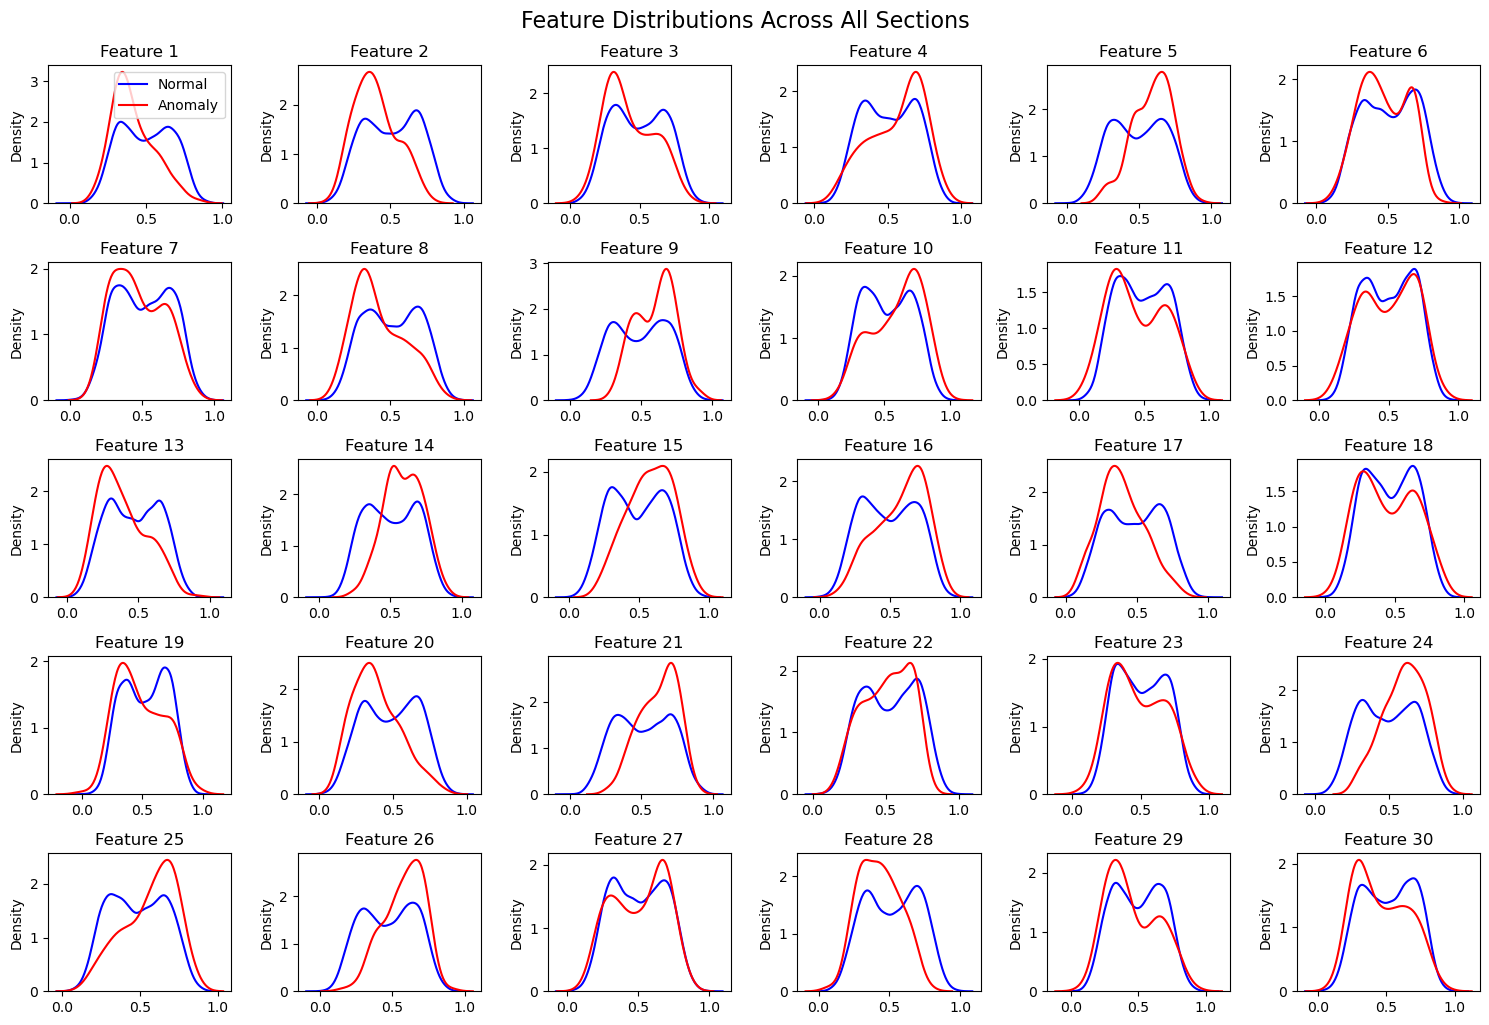

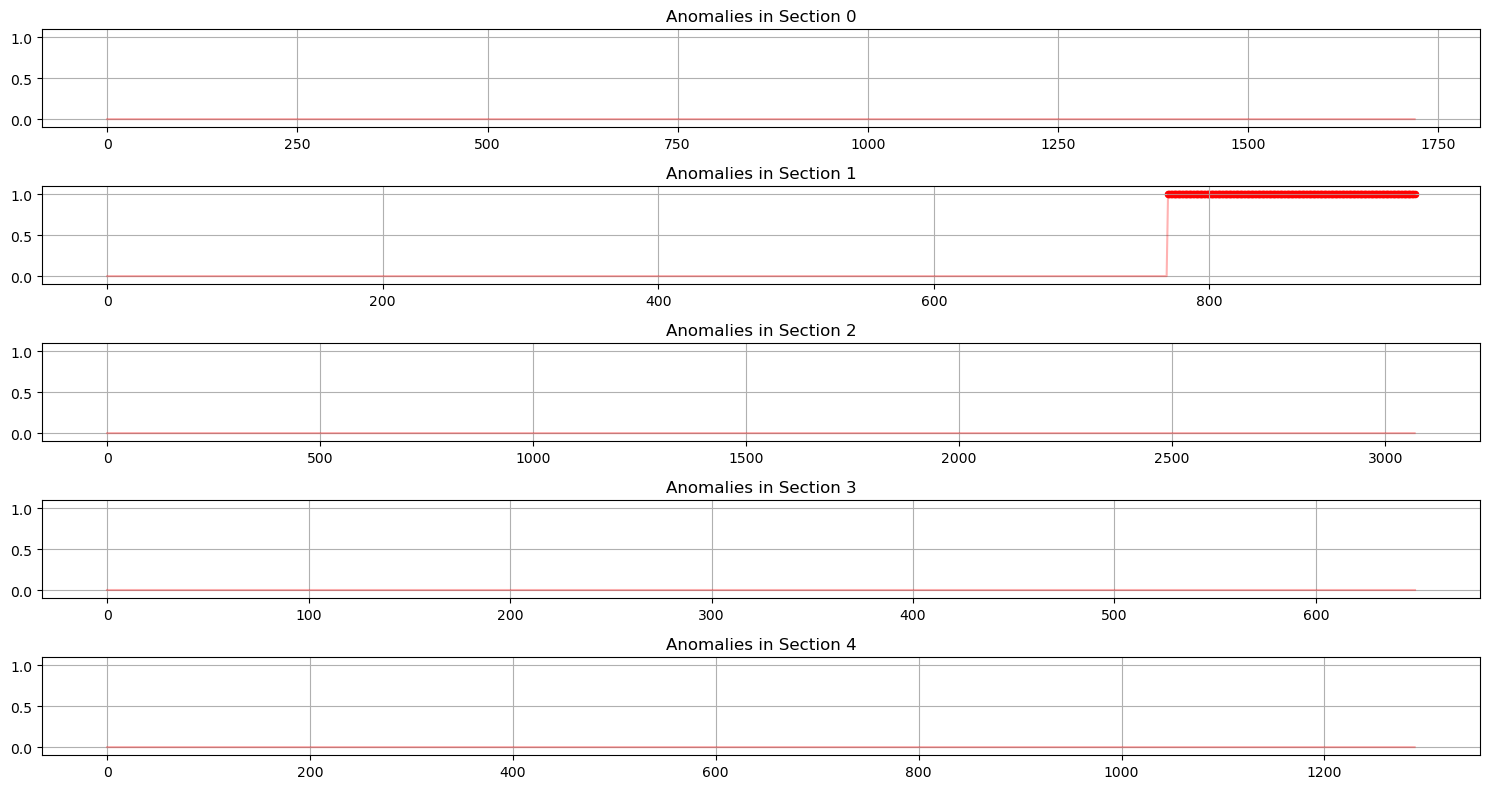

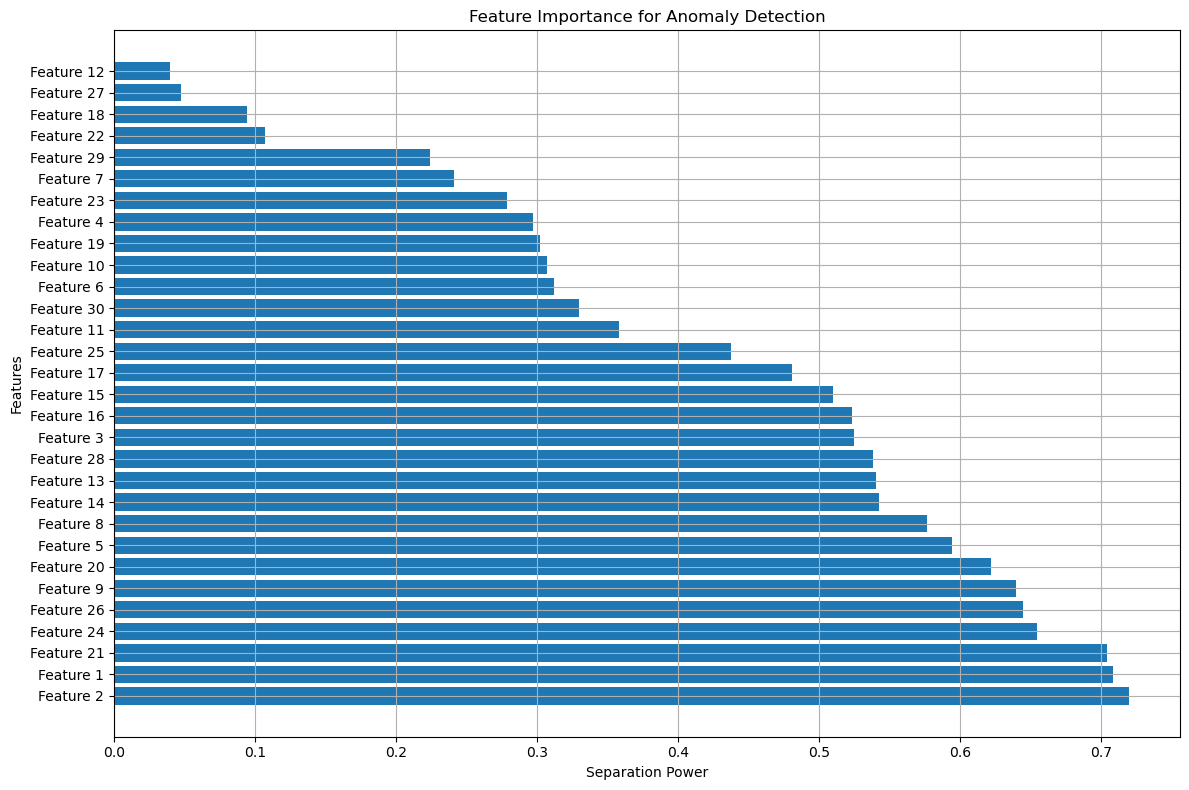

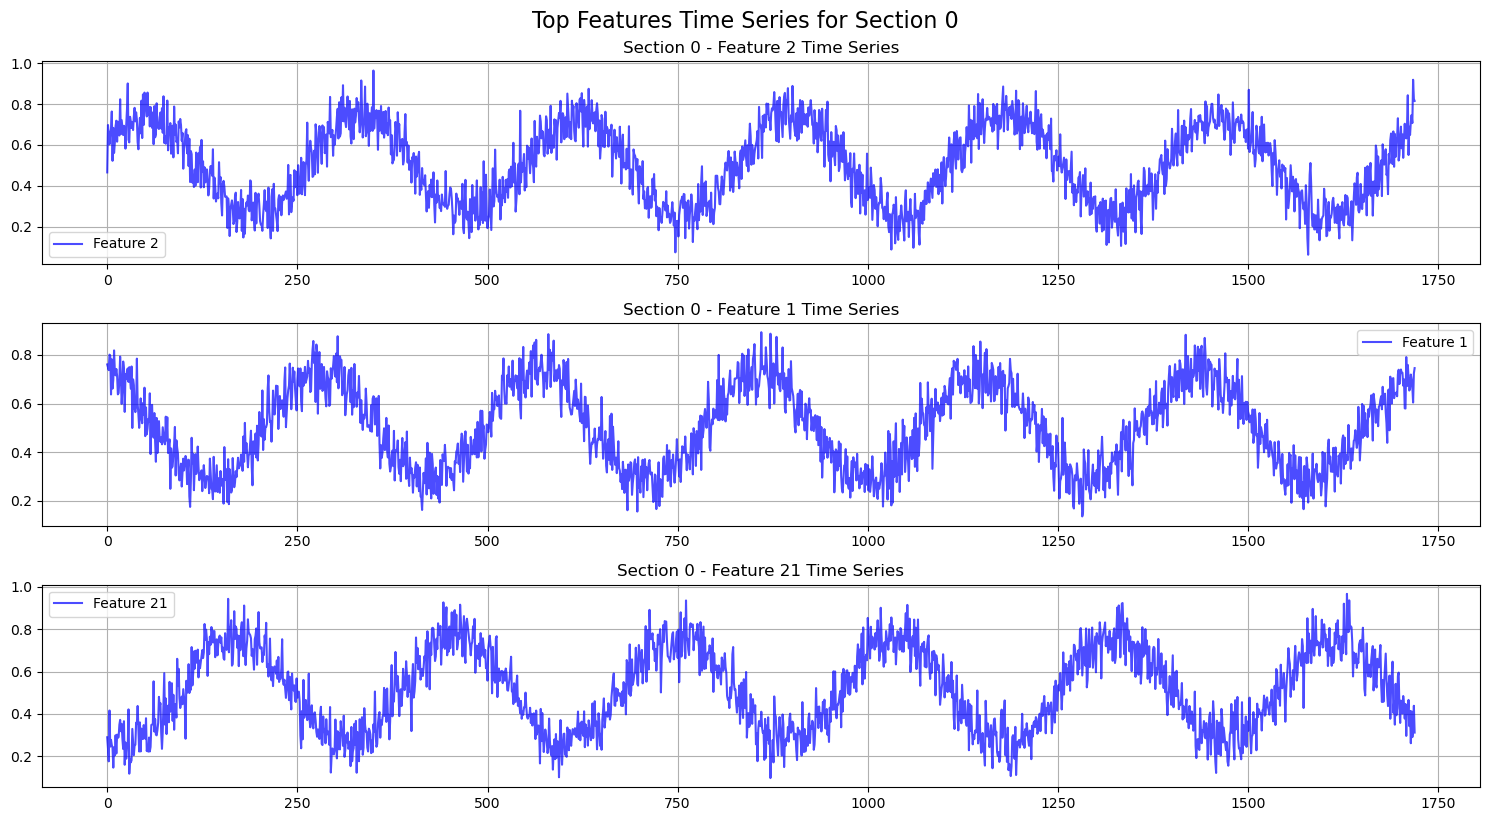

ValueError: invalid literal for int() with base 10: ''

In [6]:
from sklearn.decomposition import PCA
import seaborn as sns

def analyze_trimSyn_data(x_trn_all, x_tst_all, lab_tst_all):
    """
    Analyze and visualize the trimSyn dataset structure
    """
    # Overall dataset statistics
    print(f"Number of sections: {len(x_trn_all)}")
    total_train_samples = sum(x.shape[0] for x in x_trn_all)
    total_test_samples = sum(x.shape[0] for x in x_tst_all)
    total_anomalies = sum(np.sum(lab) for lab in lab_tst_all)
    
    print(f"Total training samples: {total_train_samples}")
    print(f"Total test samples: {total_test_samples}")
    print(f"Total anomalies: {total_anomalies}")
    print(f"Overall anomaly ratio: {total_anomalies/total_test_samples*100:.2f}%")
    
    # Create a summary table for each section
    print("\nSection-by-section statistics:")
    print("=" * 70)
    print(f"{'Section':^10}|{'Train Samples':^15}|{'Test Samples':^15}|{'Anomalies':^15}|{'Anomaly %':^15}")
    print("=" * 70)
    
    for i in range(len(x_trn_all)):
        train_samples = x_trn_all[i].shape[0]
        test_samples = x_tst_all[i].shape[0]
        anomalies = np.sum(lab_tst_all[i])
        anomaly_ratio = anomalies / test_samples * 100
        
        print(f"{i:^10}|{train_samples:^15}|{test_samples:^15}|{anomalies:^15}|{anomaly_ratio:^15.2f}")
    
    print("=" * 70)
    
    # Feature statistics across all sections
    feature_count = x_trn_all[0].shape[1]
    print(f"\nFeature count: {feature_count}")
    
    # Visualize the data
    visualize_data_summary(x_trn_all, x_tst_all, lab_tst_all)

def visualize_data_summary(x_trn_all, x_tst_all, lab_tst_all):
    """
    Create summary visualizations for the entire dataset
    """
    section_count = len(x_trn_all)
    feature_count = x_trn_all[0].shape[1]
    
    # 1. Feature distribution across sections
    plt.figure(figsize=(15, 10))
    
    # Create a grid of feature distributions
    rows = 5
    cols = 6
    features_to_plot = min(rows * cols, feature_count)
    
    for i in range(features_to_plot):
        plt.subplot(rows, cols, i+1)
        
        # Collect data for this feature across all sections
        all_normal_values = []
        all_anomaly_values = []
        
        for section_idx in range(section_count):
            normal_indices = lab_tst_all[section_idx] == 0
            anomaly_indices = lab_tst_all[section_idx] == 1
            
            all_normal_values.extend(x_tst_all[section_idx][normal_indices, i])
            all_anomaly_values.extend(x_tst_all[section_idx][anomaly_indices, i])
        
        # Plot distributions
        if len(all_normal_values) > 0:
            sns.kdeplot(all_normal_values, color='blue', label='Normal' if i == 0 else None)
        if len(all_anomaly_values) > 0:
            sns.kdeplot(all_anomaly_values, color='red', label='Anomaly' if i == 0 else None)
            
        plt.title(f'Feature {i+1}')
        if i == 0:
            plt.legend()
        
    plt.tight_layout()
    plt.suptitle('Feature Distributions Across All Sections', y=1.02, fontsize=16)
    plt.show()
    
    # 2. Anomaly distribution over time by section
    plt.figure(figsize=(15, 8))
    
    for i in range(section_count):
        plt.subplot(section_count, 1, i+1)
        
        anomaly_indices = np.where(lab_tst_all[i] == 1)[0]
        plt.plot(np.arange(len(lab_tst_all[i])), lab_tst_all[i], 'r-', alpha=0.3)
        if len(anomaly_indices) > 0:
            plt.scatter(anomaly_indices, np.ones_like(anomaly_indices), color='red', s=20)
        
        plt.title(f'Anomalies in Section {i}')
        plt.ylim(-0.1, 1.1)
        plt.grid(True)
        
    plt.tight_layout()
    plt.show()
    
    # 3. Comparison of feature importance for anomaly detection
    plt.figure(figsize=(12, 8))
    
    # Calculate feature separation power
    feature_separation = []
    
    for feat_idx in range(feature_count):
        separation_power = 0
        
        for section_idx in range(section_count):
            normal_data = x_tst_all[section_idx][lab_tst_all[section_idx] == 0, feat_idx]
            anomaly_data = x_tst_all[section_idx][lab_tst_all[section_idx] == 1, feat_idx]
            
            if len(normal_data) > 0 and len(anomaly_data) > 0:
                # Calculate separation using mean difference normalized by pooled std
                normal_mean = np.mean(normal_data)
                anomaly_mean = np.mean(anomaly_data)
                normal_std = np.std(normal_data)
                anomaly_std = np.std(anomaly_data)
                
                # Pooled standard deviation
                pooled_std = np.sqrt((normal_std**2 + anomaly_std**2) / 2)
                
                # Effect size (Cohen's d)
                if pooled_std > 0:
                    effect_size = abs(normal_mean - anomaly_mean) / pooled_std
                    separation_power += effect_size
        
        feature_separation.append(separation_power)
    
    # Sort features by separation power
    sorted_indices = np.argsort(feature_separation)[::-1]
    sorted_separation = [feature_separation[i] for i in sorted_indices]
    sorted_labels = [f'Feature {i+1}' for i in sorted_indices]
    
    plt.barh(range(feature_count), sorted_separation, tick_label=sorted_labels)
    plt.title('Feature Importance for Anomaly Detection')
    plt.xlabel('Separation Power')
    plt.ylabel('Features')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
    # 4. Time series visualization for top features
    top_features = sorted_indices[:3]  # Top 3 features
    
    for section_idx in range(section_count):
        plt.figure(figsize=(15, 8))
        
        for i, feat_idx in enumerate(top_features):
            plt.subplot(len(top_features), 1, i+1)
            
            # Plot the feature time series
            plt.plot(x_tst_all[section_idx][:, feat_idx], 'b-', alpha=0.7, label=f'Feature {feat_idx+1}')
            
            # Highlight anomaly points
            anomaly_indices = np.where(lab_tst_all[section_idx] == 1)[0]
            if len(anomaly_indices) > 0:
                plt.scatter(anomaly_indices, x_tst_all[section_idx][anomaly_indices, feat_idx], 
                           color='red', s=20, marker='x', label='Anomaly')
                
                # Add vertical lines for anomalies
                for idx in anomaly_indices:
                    plt.axvline(x=idx, color='r', linestyle='--', alpha=0.2)
            
            plt.title(f'Section {section_idx} - Feature {feat_idx+1} Time Series')
            plt.legend()
            plt.grid(True)
            
        plt.tight_layout()
        plt.suptitle(f'Top Features Time Series for Section {section_idx}', y=1.02, fontsize=16)
        plt.show()
        
        # Ask to continue if not the last section
        if section_idx < section_count - 1:
            response = input(f"Continue to Section {section_idx+1}? (y/n): ")
            if response.lower() != 'y':
                break

def visualize_section_detail(x_trn, x_tst, lab_tst, section_idx):
    """
    Detailed visualization for a specific section
    """
    print(f"\nDetailed Analysis of Section {section_idx}")
    print("=" * 50)
    print(f"Training data shape: {x_trn.shape}")
    print(f"Test data shape: {x_tst.shape}")
    print(f"Anomaly count: {np.sum(lab_tst)}")
    print(f"Anomaly ratio: {np.mean(lab_tst)*100:.2f}%")
    
    # 1. PCA visualization
    pca = PCA(n_components=2)
    x_tst_pca = pca.fit_transform(x_tst)
    
    plt.figure(figsize=(10, 8))
    plt.scatter(x_tst_pca[lab_tst==0, 0], x_tst_pca[lab_tst==0, 1], 
               c='blue', label='Normal', alpha=0.5, s=10)
    
    if np.sum(lab_tst) > 0:
        plt.scatter(x_tst_pca[lab_tst==1, 0], x_tst_pca[lab_tst==1, 1], 
                   c='red', label='Anomaly', alpha=0.7, s=30)
    
    plt.title(f'PCA Visualization of Section {section_idx}')
    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2f})')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2f})')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    # 2. Feature correlation heatmap
    plt.figure(figsize=(10, 8))
    corr_matrix = np.corrcoef(x_tst.T)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # Create mask for upper triangle
    sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', center=0, annot=False,
                square=True, linewidths=.5, vmin=-1, vmax=1)
    plt.title(f'Feature Correlation Matrix - Section {section_idx}')
    plt.tight_layout()
    plt.show()
    
    # 3. Anomaly time series with highlighted anomalies
    if np.sum(lab_tst) > 0:
        anomaly_indices = np.where(lab_tst == 1)[0]
        
        # Find sequences of consecutive anomalies
        anomaly_sequences = []
        current_seq = [anomaly_indices[0]]
        
        for i in range(1, len(anomaly_indices)):
            if anomaly_indices[i] == anomaly_indices[i-1] + 1:
                current_seq.append(anomaly_indices[i])
            else:
                anomaly_sequences.append(current_seq)
                current_seq = [anomaly_indices[i]]
        
        anomaly_sequences.append(current_seq)
        
        print(f"Found {len(anomaly_sequences)} anomaly sequences")
        for i, seq in enumerate(anomaly_sequences[:5]):  # Show first 5 sequences
            print(f"Sequence {i+1}: {len(seq)} points from index {seq[0]} to {seq[-1]}")
        
        # Visualize each anomaly sequence with context
        for i, seq in enumerate(anomaly_sequences[:3]):  # First 3 sequences only
            center_idx = seq[len(seq)//2]
            window_size = 50
            start_idx = max(0, center_idx - window_size)
            end_idx = min(len(x_tst), center_idx + window_size)
            
            plt.figure(figsize=(15, 10))
            
            # Plot top 5 features
            for j in range(min(5, x_tst.shape[1])):
                plt.subplot(5, 1, j+1)
                plt.plot(range(start_idx, end_idx), x_tst[start_idx:end_idx, j], 'b-', label=f'Feature {j+1}')
                
                # Highlight anomaly region
                for idx in range(start_idx, end_idx):
                    if lab_tst[idx] == 1:
                        plt.axvspan(idx-0.5, idx+0.5, color='red', alpha=0.2)
                
                plt.title(f'Feature {j+1}')
                plt.grid(True)
                
                # Add anomaly markers
                anomaly_in_window = [idx for idx in range(start_idx, end_idx) if lab_tst[idx] == 1]
                if anomaly_in_window:
                    plt.scatter(anomaly_in_window, x_tst[anomaly_in_window, j], color='red', marker='x')
            
            plt.suptitle(f'Anomaly Sequence {i+1} (Section {section_idx})', y=1.02)
            plt.tight_layout()
            plt.show()

# Run the analysis
analyze_trimSyn_data(x_trn_all, x_tst_all, lab_tst_all)

# Ask user which section to analyze in detail
section_to_analyze = int(input("Enter section number for detailed analysis (0-4): "))
if 0 <= section_to_analyze < len(x_trn_all):
    visualize_section_detail(
        x_trn_all[section_to_analyze], 
        x_tst_all[section_to_analyze], 
        lab_tst_all[section_to_analyze], 
        section_to_analyze
    )


Visualizing Section 0
Section 0 Statistics:
Training data shape: (10000, 30)
Test data shape: (1720, 30)
Test label shape: (1720,)
Anomaly ratio: 0.00%


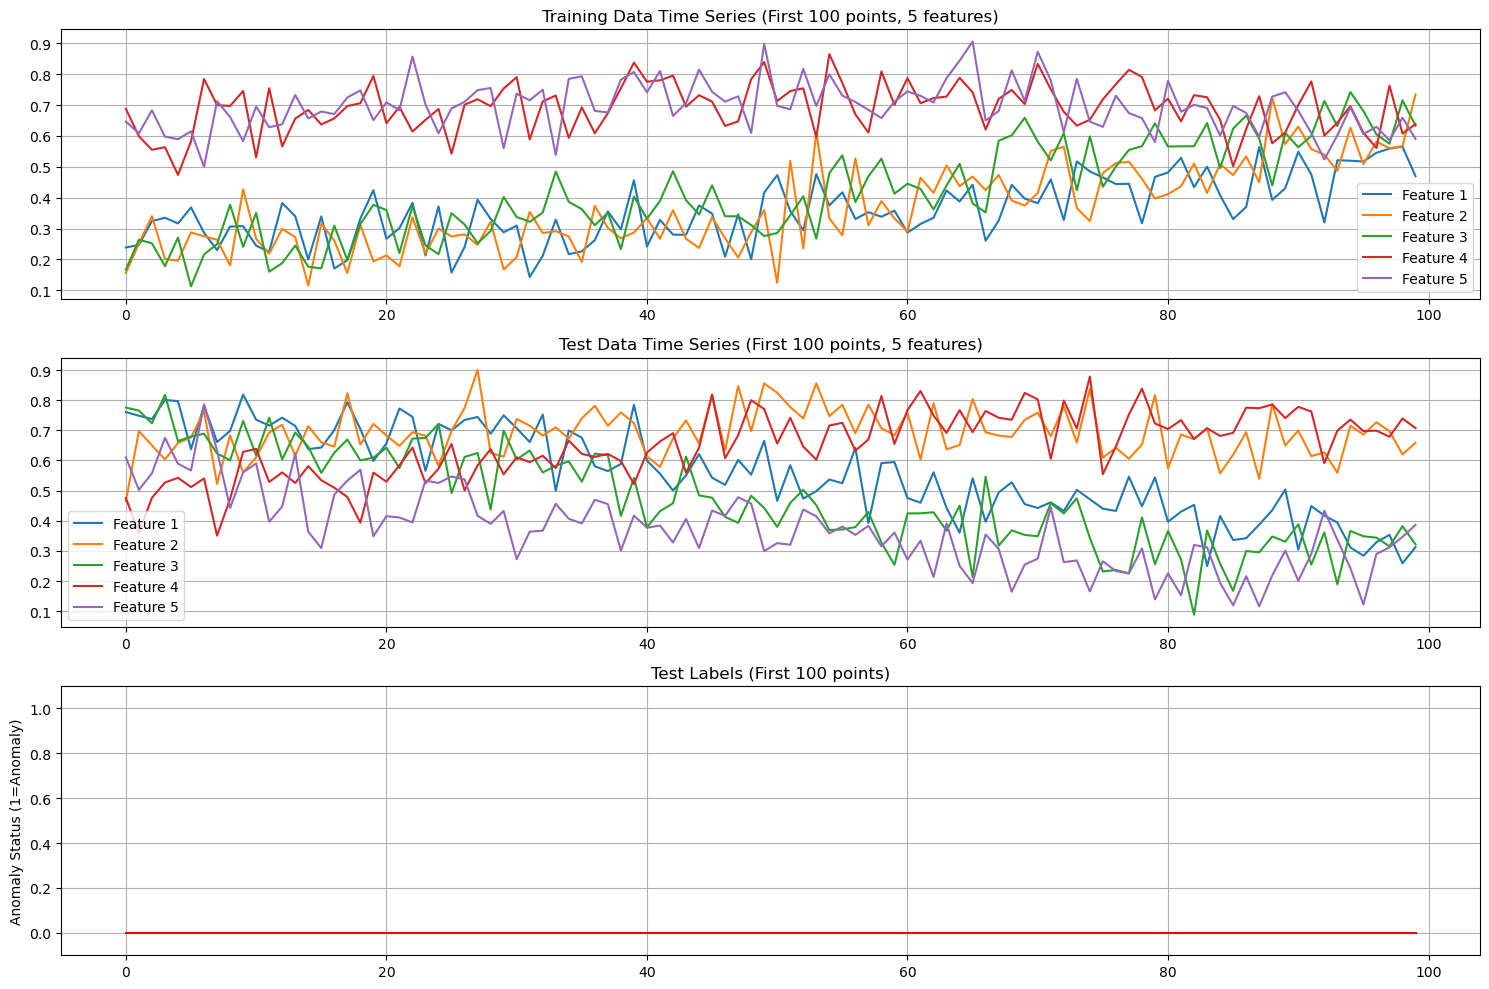

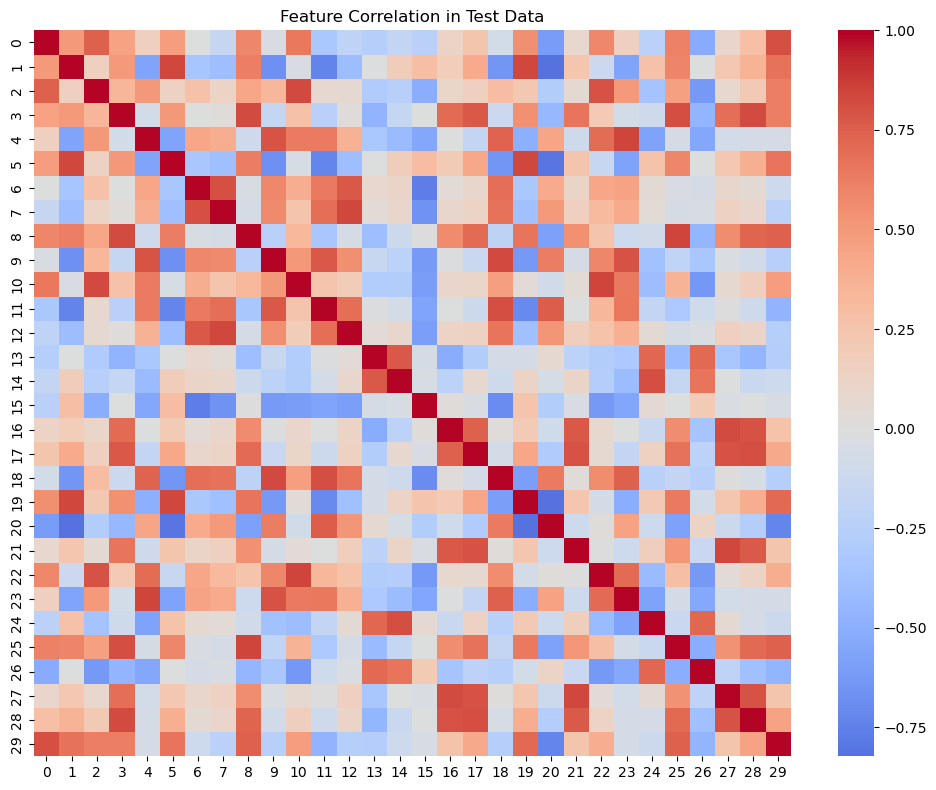

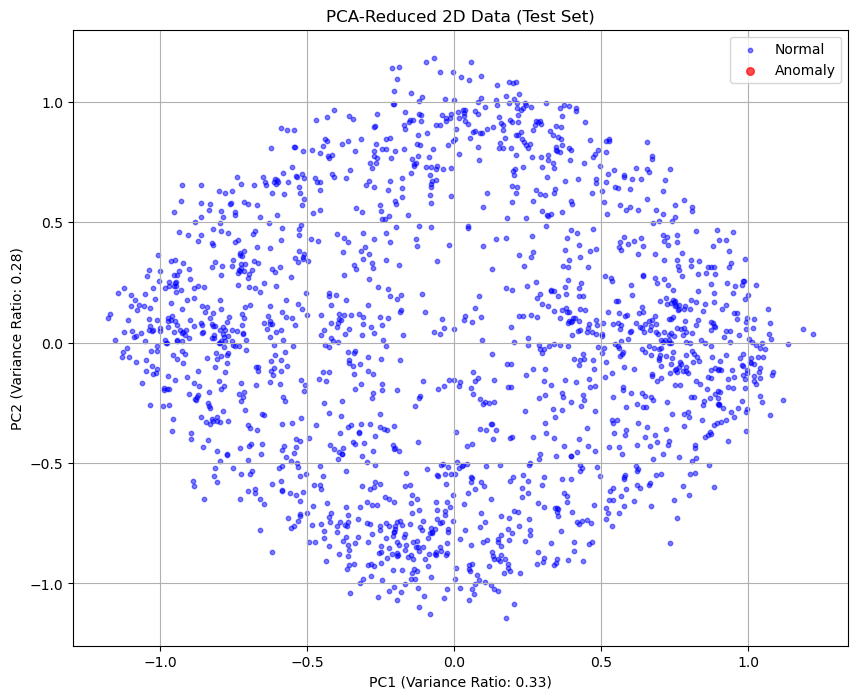

PCA explained variance ratio: [0.32878355 0.2768465 ]


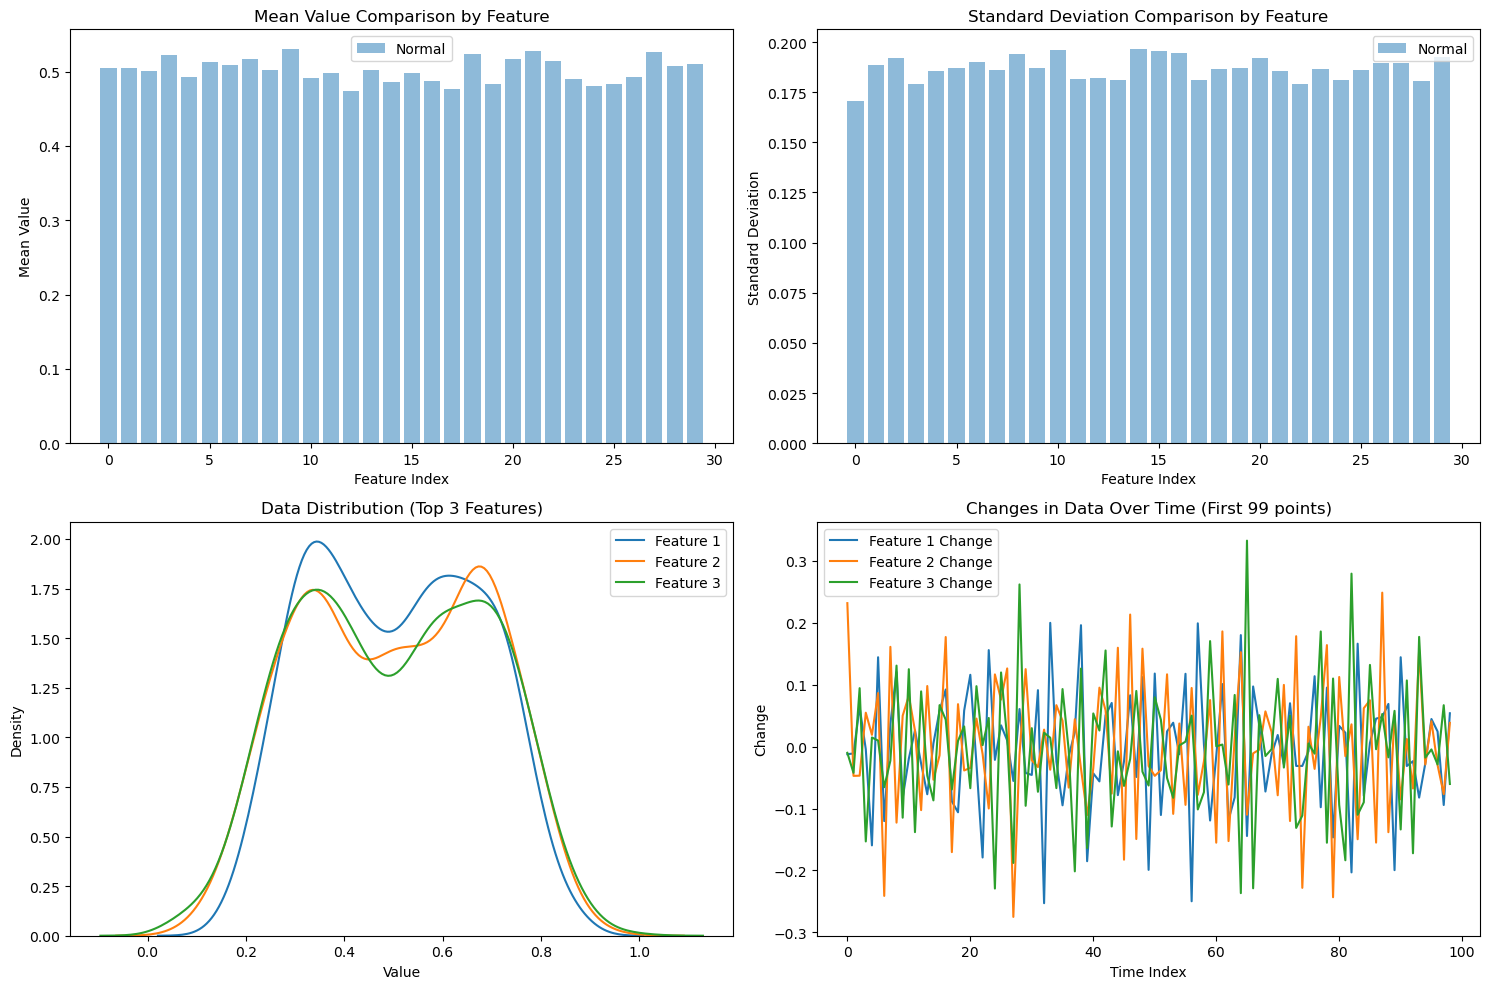

In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns

def visualize_trimSyn_data(x_trn_all, x_tst_all, lab_tst_all, section_idx=0):
    """
    Function to visualize trimSyn data
    
    Parameters:
    - x_trn_all: List of training data
    - x_tst_all: List of test data
    - lab_tst_all: List of test labels
    - section_idx: Index of section to visualize
    """
    # 1. Print basic statistics
    x_trn = x_trn_all[section_idx]
    x_tst = x_tst_all[section_idx]
    lab_tst = lab_tst_all[section_idx]
    
    print(f"Section {section_idx} Statistics:")
    print(f"Training data shape: {x_trn.shape}")
    print(f"Test data shape: {x_tst.shape}")
    print(f"Test label shape: {lab_tst.shape}")
    print(f"Anomaly ratio: {np.mean(lab_tst)*100:.2f}%")
    
    # 2. Time series plot
    plt.figure(figsize=(15, 10))
    
    # 2.1 Visualize training data (first 5 features)
    plt.subplot(3, 1, 1)
    features_to_plot = min(5, x_trn.shape[1])
    for i in range(features_to_plot):
        plt.plot(x_trn[:100, i], label=f'Feature {i+1}')
    plt.title(f'Training Data Time Series (First 100 points, {features_to_plot} features)')
    plt.legend()
    plt.grid(True)
    
    # 2.2 Visualize test data (first 5 features)
    plt.subplot(3, 1, 2)
    for i in range(features_to_plot):
        plt.plot(x_tst[:100, i], label=f'Feature {i+1}')
    plt.title(f'Test Data Time Series (First 100 points, {features_to_plot} features)')
    plt.legend()
    plt.grid(True)
    
    # 2.3 Visualize test labels
    plt.subplot(3, 1, 3)
    plt.plot(lab_tst[:100], 'r', label='Anomaly Labels')
    plt.title('Test Labels (First 100 points)')
    plt.ylabel('Anomaly Status (1=Anomaly)')
    plt.ylim(-0.1, 1.1)
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()
    
    # 3. Anomaly distribution visualization
    if np.sum(lab_tst) > 0:  # If anomalies exist
        anomaly_indices = np.where(lab_tst == 1)[0]
        print(f"Anomaly occurrence points: {anomaly_indices}")
        
        plt.figure(figsize=(15, 5))
        plt.plot(np.arange(len(lab_tst)), lab_tst, 'r-', alpha=0.5)
        plt.scatter(anomaly_indices, np.ones_like(anomaly_indices), color='red', marker='o')
        plt.title('Anomaly Distribution')
        plt.xlabel('Time Index')
        plt.ylabel('Anomaly Status')
        plt.ylim(-0.1, 1.1)
        plt.grid(True)
        plt.show()
        
        # Check patterns around anomalies (around first anomaly)
        if len(anomaly_indices) > 0:
            first_anomaly = anomaly_indices[0]
            window_size = 20
            start_idx = max(0, first_anomaly - window_size)
            end_idx = min(len(x_tst), first_anomaly + window_size)
            
            plt.figure(figsize=(12, 6))
            for i in range(features_to_plot):
                plt.plot(np.arange(start_idx, end_idx), x_tst[start_idx:end_idx, i], label=f'Feature {i+1}')
            
            # Highlight anomaly regions
            anomaly_in_window = anomaly_indices[(anomaly_indices >= start_idx) & (anomaly_indices < end_idx)]
            for idx in anomaly_in_window:
                plt.axvline(x=idx, color='r', linestyle='--', alpha=0.3)
            
            plt.title(f'Pattern Around First Anomaly (Anomaly Point: {first_anomaly})')
            plt.legend()
            plt.grid(True)
            plt.show()
    
    # 4. Feature correlation visualization
    plt.figure(figsize=(10, 8))
    correlation_matrix = np.corrcoef(x_tst.T)
    sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', center=0)
    plt.title('Feature Correlation in Test Data')
    plt.tight_layout()
    plt.show()
    
    # 5. PCA dimension reduction and anomaly visualization
    if x_tst.shape[1] > 2:
        pca = PCA(n_components=2)
        x_tst_pca = pca.fit_transform(x_tst)
        
        plt.figure(figsize=(10, 8))
        plt.scatter(x_tst_pca[lab_tst==0, 0], x_tst_pca[lab_tst==0, 1], 
                   c='blue', label='Normal', alpha=0.5, s=10)
        plt.scatter(x_tst_pca[lab_tst==1, 0], x_tst_pca[lab_tst==1, 1], 
                   c='red', label='Anomaly', alpha=0.7, s=30)
        plt.title('PCA-Reduced 2D Data (Test Set)')
        plt.xlabel(f'PC1 (Variance Ratio: {pca.explained_variance_ratio_[0]:.2f})')
        plt.ylabel(f'PC2 (Variance Ratio: {pca.explained_variance_ratio_[1]:.2f})')
        plt.legend()
        plt.grid(True)
        plt.show()
        
        print(f"PCA explained variance ratio: {pca.explained_variance_ratio_}")
    
    # 6. Statistical feature visualization
    plt.figure(figsize=(15, 10))
    
    # 6.1 Mean value comparison by feature (normal vs anomaly)
    plt.subplot(2, 2, 1)
    normal_mean = np.mean(x_tst[lab_tst==0], axis=0)
    if np.sum(lab_tst) > 0:
        anomaly_mean = np.mean(x_tst[lab_tst==1], axis=0)
        plt.bar(np.arange(len(normal_mean)), normal_mean, alpha=0.5, label='Normal')
        plt.bar(np.arange(len(anomaly_mean)), anomaly_mean, alpha=0.5, label='Anomaly')
    else:
        plt.bar(np.arange(len(normal_mean)), normal_mean, alpha=0.5, label='Normal')
    plt.title('Mean Value Comparison by Feature')
    plt.xlabel('Feature Index')
    plt.ylabel('Mean Value')
    plt.legend()
    
    # 6.2 Standard deviation comparison by feature
    plt.subplot(2, 2, 2)
    normal_std = np.std(x_tst[lab_tst==0], axis=0)
    if np.sum(lab_tst) > 0:
        anomaly_std = np.std(x_tst[lab_tst==1], axis=0)
        plt.bar(np.arange(len(normal_std)), normal_std, alpha=0.5, label='Normal')
        plt.bar(np.arange(len(anomaly_std)), anomaly_std, alpha=0.5, label='Anomaly')
    else:
        plt.bar(np.arange(len(normal_std)), normal_std, alpha=0.5, label='Normal')
    plt.title('Standard Deviation Comparison by Feature')
    plt.xlabel('Feature Index')
    plt.ylabel('Standard Deviation')
    plt.legend()
    
    # 6.3 Data distribution (histogram)
    plt.subplot(2, 2, 3)
    for i in range(min(3, x_tst.shape[1])):
        sns.kdeplot(x_tst[:, i], label=f'Feature {i+1}')
    plt.title('Data Distribution (Top 3 Features)')
    plt.xlabel('Value')
    plt.ylabel('Density')
    plt.legend()
    
    # 6.4 Visualize changes in data over time (derivative)
    plt.subplot(2, 2, 4)
    for i in range(min(3, x_tst.shape[1])):
        changes = np.diff(x_tst[:100, i])
        plt.plot(changes, label=f'Feature {i+1} Change')
    plt.title('Changes in Data Over Time (First 99 points)')
    plt.xlabel('Time Index')
    plt.ylabel('Change')
    plt.legend()
    
    plt.tight_layout()
    plt.show()

# Visualize all sections
for section_idx in range(len(x_trn_all)):
    print(f"\n{'='*50}")
    print(f"Visualizing Section {section_idx}")
    print(f"{'='*50}")
    visualize_trimSyn_data(x_trn_all, x_tst_all, lab_tst_all, section_idx)
    
    # If multiple sections exist, ask whether to continue
    if section_idx < len(x_trn_all) - 1:
        response = input("Visualize next section? (y/n): ")
        if response.lower() != 'y':
            break

In [82]:
def process_section(x_trn, x_tst, lab_tst, num_epochs, batch_size, lr, weight_decay, hidden_dim, num_heads, device):
    """단일 섹션 처리 함수"""
    # 데이터 변환
    if isinstance(x_trn, list):
        x_trn = np.array(x_trn)
    if isinstance(x_tst, list):
        x_tst = np.array(x_tst)
    if isinstance(lab_tst, list):
        try:
            lab_tst = np.array(lab_tst)
        except ValueError:
            # 불규칙한 길이의 리스트 처리
            max_len = max(len(x) for x in lab_tst)
            lab_tst = np.array([np.pad(x, (0, max_len - len(x)), 'constant') for x in lab_tst])
    
    # 차원 확인 및 처리
    if len(x_trn.shape) == 2:
        x_trn = x_trn[:, np.newaxis, :]
        x_tst = x_tst[:, np.newaxis, :]
    
    # 데이터 정규화
    x_trn_mean = np.mean(x_trn, axis=(0, 1), keepdims=True)
    x_trn_std = np.std(x_trn, axis=(0, 1), keepdims=True)
    x_trn_std[x_trn_std < 1e-10] = 1.0
    
    x_trn_norm = (x_trn - x_trn_mean) / x_trn_std
    x_tst_norm = (x_tst - x_trn_mean) / x_trn_std
    
    # 시간 단계 생성
    time_steps_trn = np.tile(np.linspace(0, 1, x_trn.shape[1]), (x_trn.shape[0], 1))
    time_steps_tst = np.tile(np.linspace(0, 1, x_tst.shape[1]), (x_tst.shape[0], 1))
    
    # PyTorch 데이터셋 및 로더 생성
    train_dataset = TensorDataset(
        torch.tensor(x_trn_norm, dtype=torch.float32),
        torch.tensor(time_steps_trn, dtype=torch.float32)
    )
    
    test_dataset = TensorDataset(
        torch.tensor(x_tst_norm, dtype=torch.float32),
        torch.tensor(time_steps_tst, dtype=torch.float32),
        torch.tensor(lab_tst, dtype=torch.float32)
    )
    
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size)
    
    # 모델 초기화
    input_dim = x_trn.shape[2]
    model = AnomalyDetector(input_dim=input_dim, hidden_dim=hidden_dim, num_heads=num_heads)
    model = model.to(device)
    
    # 옵티마이저 및 손실 함수
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.BCELoss()
    
    # 모델 훈련
    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0
        
        for x_batch, time_steps in train_loader:
            x_batch = x_batch.to(device)
            time_steps = time_steps.to(device)
            
            optimizer.zero_grad()
            
            outputs = model(x_batch, time_steps)
            clean_loss = criterion(outputs, torch.zeros_like(outputs))
            
            # 인공적 이상치 생성
            noise_ratio = 0.1
            noise_mask = (torch.rand_like(x_batch[:, :, 0:1]) < noise_ratio).float()
            noise = torch.randn_like(x_batch) * 0.5 * noise_mask
            noisy_x = x_batch + noise
            
            noisy_outputs = model(noisy_x, time_steps)
            noisy_loss = criterion(noisy_outputs, torch.ones_like(noisy_outputs) * 0.8)
            
            loss = clean_loss + 0.5 * noisy_loss
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
        
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss/len(train_loader):.6f}")
    
    # 평가
    model.eval()
    all_scores = []
    all_labels = []
    
    with torch.no_grad():
        for x_batch, time_steps, labels in test_loader:
            x_batch = x_batch.to(device)
            time_steps = time_steps.to(device)
            labels = labels.to(device)
            
            anomaly_scores = model(x_batch, time_steps)
            
            all_scores.append(anomaly_scores.cpu().numpy())
            all_labels.append(labels.cpu().numpy())
    
    anomaly_scores = np.concatenate(all_scores).flatten()
    true_labels = np.concatenate(all_labels).flatten()
    
    # 최적 임계값 찾기
    best_f1 = 0
    best_threshold = 0.5
    best_precision = 0
    best_recall = 0
    
    for threshold in np.arange(0.1, 0.95, 0.05):
        predictions = (anomaly_scores > threshold).astype(int)
        
        if np.sum(predictions) == 0 or np.sum(predictions) == len(predictions):
            continue
        
        precision = precision_score(true_labels, predictions, zero_division=0)
        recall = recall_score(true_labels, predictions, zero_division=0)
        f1 = f1_score(true_labels, predictions, zero_division=0)
        
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_precision = precision
            best_recall = recall
    
    if np.sum(true_labels) > 0 and np.sum(true_labels) < len(true_labels):
        auc = roc_auc_score(true_labels, anomaly_scores)
    else:
        auc = 0.5
    
    return {
        'model': model,
        'metrics': {
            'threshold': best_threshold,
            'precision': best_precision,
            'recall': best_recall,
            'f1': best_f1,
            'auc': auc
        }
    }

In [83]:
def train_anomaly_detector(data, dataset_name='dataset', num_epochs=20, batch_size=64, lr=1e-4, weight_decay=1e-5):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"사용 장치: {device}")
    
    # 데이터 형식 확인
    if 'x_trn' in data and 'x_tst' in data and 'lab_tst' in data:
        x_trn = data['x_trn']
        x_tst = data['x_tst']
        lab_tst = data['lab_tst']
        
        if isinstance(x_trn, list) and isinstance(x_tst, list) and isinstance(lab_tst, list):
            # 리스트 형식 - 다중 섹션으로 처리
            print(f"{dataset_name}: 리스트 형식 감지, {len(x_trn)}개 섹션으로 처리")
            all_results = []
            
            for i in range(len(x_trn)):
                print(f"\n섹션 {i+1}/{len(x_trn)} 처리 중")
                result = process_section(
                    x_trn[i], x_tst[i], lab_tst[i],
                    num_epochs=num_epochs,
                    batch_size=batch_size,
                    lr=lr,
                    weight_decay=weight_decay,
                    hidden_dim=128,
                    num_heads=4,
                    device=device
                )
                all_results.append(result)
            
            # 평균 성능 계산
            avg_precision = np.mean([r['metrics']['precision'] for r in all_results])
            avg_recall = np.mean([r['metrics']['recall'] for r in all_results])
            avg_f1 = np.mean([r['metrics']['f1'] for r in all_results])
            avg_auc = np.mean([r['metrics']['auc'] for r in all_results])
            
            print(f"\n{dataset_name} 평균 성능:")
            print(f"Precision: {avg_precision:.4f}")
            print(f"Recall: {avg_recall:.4f}")
            print(f"F1: {avg_f1:.4f}")
            print(f"AUC: {avg_auc:.4f}")
            
            return {
                'section_results': all_results,
                'avg_metrics': {
                    'precision': avg_precision,
                    'recall': avg_recall,
                    'f1': avg_f1,
                    'auc': avg_auc
                }
            }
        else:
            # 단일 데이터셋
            print(f"{dataset_name}: 단일 데이터셋 처리")
            result = process_section(
                x_trn, x_tst, lab_tst,
                num_epochs=num_epochs,
                batch_size=batch_size,
                lr=lr,
                weight_decay=weight_decay,
                hidden_dim=128,
                num_heads=4,
                device=device
            )
            
            print(f"\n{dataset_name} 성능:")
            print(f"Precision: {result['metrics']['precision']:.4f}")
            print(f"Recall: {result['metrics']['recall']:.4f}")
            print(f"F1: {result['metrics']['f1']:.4f}")
            print(f"AUC: {result['metrics']['auc']:.4f}")
            
            return result
    
    elif 'trn' in data and 'tst' in data and 'lab' in data:
        # 다중 섹션 형식
        x_trn_all = data['trn']
        x_tst_all = data['tst']
        lab_tst_all = data['lab']
        
        print(f"{dataset_name}: 다중 섹션 형식 감지, {len(x_trn_all)}개 섹션")
        all_results = []
        
        for i in range(len(x_trn_all)):
            print(f"\n섹션 {i+1}/{len(x_trn_all)} 처리 중")
            result = process_section(
                x_trn_all[i], x_tst_all[i], lab_tst_all[i],
                num_epochs=num_epochs,
                batch_size=batch_size,
                lr=lr,
                weight_decay=weight_decay,
                hidden_dim=128,
                num_heads=4,
                device=device
            )
            all_results.append(result)
        
        # 평균 성능 계산
        avg_precision = np.mean([r['metrics']['precision'] for r in all_results])
        avg_recall = np.mean([r['metrics']['recall'] for r in all_results])
        avg_f1 = np.mean([r['metrics']['f1'] for r in all_results])
        avg_auc = np.mean([r['metrics']['auc'] for r in all_results])
        
        print(f"\n{dataset_name} 평균 성능:")
        print(f"Precision: {avg_precision:.4f}")
        print(f"Recall: {avg_recall:.4f}")
        print(f"F1: {avg_f1:.4f}")
        print(f"AUC: {avg_auc:.4f}")
        
        return {
            'section_results': all_results,
            'avg_metrics': {
                'precision': avg_precision,
                'recall': avg_recall,
                'f1': avg_f1,
                'auc': avg_auc
            }
        }
    
    else:
        raise ValueError("지원하지 않는 데이터 형식입니다.")


In [84]:
# trimSyn 데이터셋 로드 및 적용
from datasets.SMD.preprocess_SMD import SMD_Dataset
import pickle as pk

trimSyn_path = './data/MSCRED/trimSyn.pk'
with open(trimSyn_path, 'rb') as pkf:
    trimSyn_data = pk.load(pkf)

results = train_anomaly_detector(
    data=trimSyn_data,
    dataset_name='trimSyn',
    num_epochs=15,
    batch_size=256
)

사용 장치: cpu
trimSyn: 리스트 형식 감지, 5개 섹션으로 처리

섹션 1/5 처리 중
Epoch 1/15, Loss: 1.053473
Epoch 5/15, Loss: 0.932744
Epoch 10/15, Loss: 0.926282
Epoch 15/15, Loss: 0.881615

섹션 2/5 처리 중
Epoch 1/15, Loss: 1.064183
Epoch 5/15, Loss: 0.935583
Epoch 10/15, Loss: 0.926439
Epoch 15/15, Loss: 0.877787

섹션 3/5 처리 중
Epoch 1/15, Loss: 1.047852
Epoch 5/15, Loss: 0.934485
Epoch 10/15, Loss: 0.924309
Epoch 15/15, Loss: 0.871207

섹션 4/5 처리 중
Epoch 1/15, Loss: 1.056309
Epoch 5/15, Loss: 0.933232
Epoch 10/15, Loss: 0.925601
Epoch 15/15, Loss: 0.878790

섹션 5/5 처리 중
Epoch 1/15, Loss: 1.062101
Epoch 5/15, Loss: 0.932637
Epoch 10/15, Loss: 0.926260
Epoch 15/15, Loss: 0.879952

trimSyn 평균 성능:
Precision: 0.0379
Recall: 0.2000
F1: 0.0638
AUC: 0.5045


In [25]:
### New data 
# MSL

from torch.utils.data import Dataset
from utils.mypath import MyPath
import ast
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class MSL(Dataset):
    base_folder = ''

    def __init__(self, fname, root=MyPath.db_root_dir('msl'), train=True, transform=None, sanomaly= None, mean_data=None, std_data=None):

        super(MSL, self).__init__()
        self.root = root
        self.transform = transform
        self.sanomaly = sanomaly
        self.train = train  # training set or test set
        self.classes = ['Normal', 'Anomaly']
        self.data = []
        self.targets = []
        wsz, stride = 200, 1

        with open(os.path.join(self.root, 'labeled_anomalies.csv'), 'r') as file:
            csv_reader = pandas.read_csv(file, delimiter=',')

        data_info = csv_reader[csv_reader['chan_id'] == fname]

        if self.train:
            self.base_folder += 'train'
        else:
            self.base_folder += 'test'
            labels = []
            for index, row in data_info.iterrows():
                anomalies = ast.literal_eval(row['anomaly_sequences'])
                length = row.iloc[-1]
                label = np.zeros([length], dtype=bool)
                for anomaly in anomalies:
                    label[anomaly[0]:anomaly[1] + 1] = True
                labels.extend(label)
            self.targets = np.asarray(labels)

            self.mean, self.std = mean_data, std_data

        file_path = os.path.join(self.root, self.base_folder, fname+'.npy')
        temp = np.load(file_path)
        if np.any(sum(np.isnan(temp))!=0):
            print('Data contains NaN which replaced with zero')
            temp = np.nan_to_num(temp)

        if self.train:
            self.mean = np.mean(temp, axis=0)
            self.std = np.std(temp , axis=0)
            # min_column = np.amin(temp, axis=0)
            # max_column = np.amax(temp, axis=0)
            # self.mean, self.std = min_column, max_column 
        else:
            self.mean, self.std = mean_data, std_data
            # range_val = (std_data - mean_data) + 1e-20
            # temp = (temp - mean_data) / range_val
            self.std[self.std == 0.0] = 1.0
            temp = (temp - self.mean) / self.std

        self.data = np.asarray(temp)
        self.data, self.targets = self.convert_to_windows(wsz, stride)

    def convert_to_windows(self, w_size, stride):
        windows = []
        wlabels = []
        sz = int((self.data.shape[0]-w_size)/stride)
        for i in range(0, sz):
            st = i * stride
            w = self.data[st:st+w_size]
            if sum(self.targets[st:st+w_size]) > 0:
                lbl = 1
            else: lbl=0
                    
            windows.append(w)
            wlabels.append(lbl)
        return np.stack(windows), np.stack(wlabels)

    def __getitem__(self, index):
        """
        Args:
            index (int): Index
        Returns:
            dict: {'ts': ts, 'target': index of target class, 'meta': dict}
        """
        # ts_org = self.data[index]
        ts_org = torch.from_numpy(self.data[index]).float().to(device)  # cuda

        if len(self.targets) > 0:
            # target = self.targets[index].astype(int)
            target = torch.tensor(self.targets[index].astype(int), dtype=torch.long).to(device)
            class_name = self.classes[target]
        else:
            target = 0
            class_name = ''

        ts_size = (ts_org.shape[0], ts_org.shape[1])

        out = {'ts_org': ts_org, 'target': target, 'meta': {'ts_size': ts_size, 'index': index, 'class_name': class_name}}

        return out

    def get_ts(self, index):
        ts = self.data[index]
        return ts

    def get_info(self):
        return self.mean, self.std

    def concat_ds(self, new_ds):
        self.data = np.concatenate((self.data, new_ds.data), axis=0)
        self.targets = np.concatenate((self.targets, new_ds.targets), axis=0)

    def __len__(self):
        return len(self.data)

    def extra_repr(self):
        return "Split: {}".format("Train" if self.train is True else "Test")

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
import torch
import torch.nn as nn
from torchdiffeq import odeint

class NeuralODE(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODE, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, input_dim)

    def forward(self, t, y):
        return self.fc2(torch.relu(self.fc1(y)))

def extract_periodic_features(data):
    fft_result = np.fft.fft(data.to_numpy())
    periodic_features = np.abs(fft_result[:len(data)//2])  
    return torch.tensor(periodic_features, dtype=torch.float32)

def detect_spikes_with_periodicity(df, column_names, threshold):
    # 결측값 제거 및 데이터 준비
    data = df[column_names].dropna()
    data_tensor = torch.tensor(data.values, dtype=torch.float32)
    
    # 각 열에 대한 주기 특성 추출 및 결합
    periodic_features = []
    for col in column_names:
        periodic_feature = extract_periodic_features(data[col])
        periodic_feature = periodic_feature.unsqueeze(0).repeat(data_tensor.shape[0], 1)
        periodic_features.append(periodic_feature)
    
    periodic_features = torch.cat(periodic_features, dim=1)
    combined_input = torch.cat((data_tensor, periodic_features), dim=1)
    
    # Neural ODE 모델 초기화 및 학습
    model = NeuralODE(input_dim=combined_input.shape[1], hidden_dim=64)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    
    # ODE 솔버 실행
    t = torch.linspace(0, 1, data_tensor.size(0))
    y0 = combined_input[0].unsqueeze(0)
    solution = odeint(model, y0, t)
    
    # 스파이크 감지
    spikes = (solution[:, :, :len(column_names)] > threshold).float()
    spikes = spikes.mean(dim=(1, 2))
    
    # 원래 데이터프레임 길이에 맞추어 결과 조정
    spikes_full = np.zeros(len(df))
    valid_indices = data.index[data[column_names].notna().all(axis=1)]
    spikes_full[valid_indices] = spikes.detach().numpy()
    
    return spikes_full, data_tensor, valid_indices

def detect_anomalies(df, column_names, data_tensor, valid_indices):
    # One-Class SVM 실행
    oc_svm = OneClassSVM(kernel='rbf', gamma='auto').fit(data_tensor.numpy())
    oc_svm_predictions = oc_svm.predict(data_tensor.numpy())
    
    # 결과를 원본 데이터프레임 길이에 맞게 조정
    anomalies_full = np.zeros(len(df))
    anomalies_full[valid_indices] = (oc_svm_predictions == -1).astype(float)
    
    return anomalies_full

def visualize_results(df, column_name, spikes, anomalies):
    plt.figure(figsize=(15, 6))
    plt.plot(df['date'], df[column_name], label=column_name, marker='o', alpha=0.5)
    
    # Neural ODE 스파이크 시각화
    spike_mask = spikes > 0.5
    plt.scatter(df['date'][spike_mask], df[column_name][spike_mask], 
               color='red', label='Neural ODE Spikes', zorder=5)
    
    # One-Class SVM 이상치 시각화
    anomaly_mask = anomalies > 0.5
    plt.scatter(df['date'][anomaly_mask], df[column_name][anomaly_mask], 
               color='orange', label='One-Class SVM Anomalies', zorder=5)
    
    plt.title('Spike Detection and Anomaly Detection')
    plt.xlabel('Date')
    plt.ylabel('Values')
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

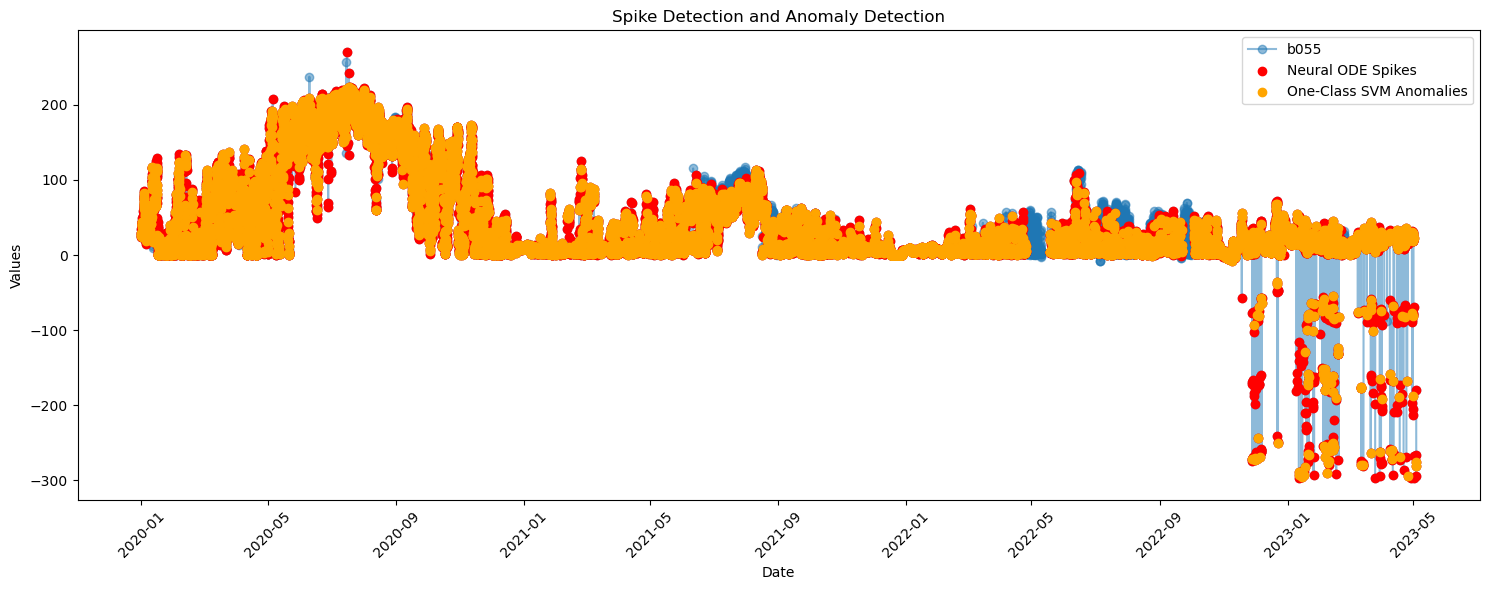

In [66]:
# 데이터 준비
columns = ['b055', 'b103', 'b166', 'b002', 'b084']
threshold = 2

# 스파이크 감지 실행
spikes, data_tensor, valid_indices = detect_spikes_with_periodicity(df, columns, threshold)

# 이상치 감지 실행
anomalies = detect_anomalies(df, columns, data_tensor, valid_indices)

# 결과 시각화
visualize_results(df, 'b055', spikes, anomalies)

In [46]:
import torch
import torch.nn as nn
import torchdiffeq  # Neural ODE library
import matplotlib.pyplot as plt

class ODEFunc(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(ODEFunc, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, input_dim)
    
    def forward(self, t, y):
        y = torch.relu(self.fc1(y))
        return self.fc2(y)

class NeuralODEModel(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODEModel, self).__init__()
        self.odefunc = ODEFunc(input_dim, hidden_dim)
    
    def forward(self, y0, t):
        return torchdiffeq.odeint(self.odefunc, y0, t)


# Training loop for Neural ODE
def train_ode_model(model, data, time, epochs=500, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    for epoch in range(epochs):
        optimizer.zero_grad()

        # Initial condition (y0) is the first observation
        y0 = data[0].unsqueeze(0)  # Ensure y0 is of shape [1, num_features]

        # Forward pass through the ODE model
        pred = model(y0, time)

        # Compute loss (reconstruction error)
        huber_loss = nn.HuberLoss()
        loss = huber_loss(pred, data.unsqueeze(0))  # Ensure data has proper shape [1, num_features, num_timesteps]

        # Backpropagation
        loss.backward()
        optimizer.step()

        if epoch % 10 == 0:
            print(f'Epoch {epoch}, Loss: {loss.item()}')

# Anomaly detection: Calculate reconstruction error as anomaly score
def detect_anomalies(model, data, time, threshold=0.1):
    y0 = data[0]
    pred = model(y0, time)
    reconstruction_error = torch.mean((pred - data) ** 2, dim=1)
    anomalies = reconstruction_error > threshold
    return anomalies, reconstruction_error

def plot_predictions(time, true_data, predicted_data):
    num_vars = true_data.shape[1]
    
    plt.figure(figsize=(12, 6 * num_vars))
    for i in range(num_vars):
        plt.subplot(num_vars, 1, i+1)
        plt.plot(time.numpy(), true_data[:, i].numpy(), label='True Data')
        plt.plot(time.numpy(), predicted_data[:, i].detach().numpy(), label='Predicted Data', linestyle='--')
        plt.xlabel('Time (hours)')
        plt.ylabel(f'Variable {i+1}')
        plt.legend()
    plt.tight_layout()
    plt.show()

In [21]:
from fancyimpute import IterativeImputer

# Initialize and train the model
csv_file_path = './CSV data/GT/GT_final_date.csv'  
df = pd.read_csv(csv_file_path)

# Convert 'date' to numerical format (e.g., hours since start)
df['date'] = pd.to_datetime(df['date'])
df['date_numeric'] = (df['date'] - df['date'].min()).dt.total_seconds() / 3600

# Include 'date_numeric' in the imputation process
df2 = df.drop(['date'], axis=1)
data = df2.values

# Initialize MICE imputer
mice_imputer = IterativeImputer()

# Perform imputation
imputed_data = mice_imputer.fit_transform(data)

# Convert imputed data back to DataFrame
imputed_df = pd.DataFrame(imputed_data, columns=df2.columns)
imputed_df['date'] = df['date'] 
imputed_df['date_numeric'] = (imputed_df['date'] - imputed_df['date'].min()).dt.total_seconds() / 3600

In [23]:
# Ensure time steps are unique and sufficiently spaced
time = torch.tensor(imputed_df['date_numeric'].values, dtype=torch.float32)
time_diff = time.diff()

# Adjust time steps if any are zero or too small
min_time_step = 1e-2  # Set a minimum allowed time step
time_diff = torch.where(time_diff == 0, min_time_step, time_diff)  # Replace zero differences

# Recalculate time from the adjusted differences
time_adjusted = torch.cumsum(time_diff, dim=0)
time_adjusted = torch.cat((torch.tensor([time[0]]), time_adjusted))  # Include the initial time

# Normalize time between 0 and 1
time_normalized = (time_adjusted - time_adjusted.min()) / (time_adjusted.max() - time_adjusted.min())

# Convert imputed data to PyTorch tensor
data = torch.tensor(imputed_df.drop(['date', 'date_numeric'], axis=1).values, dtype=torch.float32)

In [24]:
# Initialize and train the model
input_dim = data.shape[1]  # Number of features in the data
hidden_dim = 50  # Hidden dimension size

ode_model = NeuralODEModel(input_dim, hidden_dim)
train_ode_model(ode_model, data, time_normalized)

# Predict and plot
y0 = data[0].unsqueeze(0)  # Initial condition for prediction
predicted = ode_model(y0, time_normalized)

/opt/anaconda3/envs/career/lib/python3.11/site-packages/torch/nn/modules/loss.py:999: UserWarning: Using a target size (torch.Size([1, 29256, 6])) that is different to the input size (torch.Size([29256, 1, 6])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.huber_loss(input, target, reduction=self.reduction, delta=self.delta)


Epoch 0, Loss: 6429071.0
Epoch 10, Loss: 6169923.5
Epoch 20, Loss: 6042227.5
Epoch 30, Loss: 5962905.0
Epoch 40, Loss: 5904445.5
Epoch 50, Loss: 5860411.5
Epoch 60, Loss: 5819851.0
Epoch 70, Loss: 5778532.0
Epoch 80, Loss: 5736408.0
Epoch 90, Loss: 5696644.0
Epoch 100, Loss: 5656487.0
Epoch 110, Loss: 5617336.5
Epoch 120, Loss: 5577563.0
Epoch 130, Loss: 5539727.5
Epoch 140, Loss: 5502061.5
Epoch 150, Loss: 5462732.0
Epoch 160, Loss: 5426233.0
Epoch 170, Loss: 5389188.0
Epoch 180, Loss: 5354967.5
Epoch 190, Loss: 5317069.5
Epoch 200, Loss: 5283030.5
Epoch 210, Loss: 5247810.5
Epoch 220, Loss: 5215267.0
Epoch 230, Loss: 5182472.0
Epoch 240, Loss: 5152455.0
Epoch 250, Loss: 5120677.0
Epoch 260, Loss: 5091159.0
Epoch 270, Loss: 5063383.5
Epoch 280, Loss: 5035992.5
Epoch 290, Loss: 5009796.5
Epoch 300, Loss: 4984998.0
Epoch 310, Loss: 4959976.5
Epoch 320, Loss: 4936718.0
Epoch 330, Loss: 4913600.5
Epoch 340, Loss: 4891809.0
Epoch 350, Loss: 4870829.5
Epoch 360, Loss: 4850446.0
Epoch 370, L

In [27]:
import torch
import torchdiffeq
from nflows import transforms, distributions, flows

class FlowLayer(torch.nn.Module):
    def __init__(self, input_dim):
        super(FlowLayer, self).__init__()
        self.base_dist = distributions.StandardNormal([input_dim])
        self.transform = transforms.CompositeTransform([
            transforms.AffineCoupling(input_dim=input_dim // 2),
            transforms.ActNorm(input_dim),
        ])
        self.flow = flows.Flow(self.transform, self.base_dist)

    def forward(self, x):
        # Forward pass through normalizing flow
        z, log_det = self.flow._transform.forward(x)
        return z, log_det

class NeuralODEModel(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODEModel, self).__init__()
        self.odefunc = torch.nn.Sequential(
            torch.nn.Linear(input_dim, hidden_dim),
            torch.nn.Tanh(),
            torch.nn.Linear(hidden_dim, input_dim),
        )

    def forward(self, y0, t):
        return torchdiffeq.odeint(self.odefunc, y0, t)

class CombinedModel(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(CombinedModel, self).__init__()
        self.flow_layer = FlowLayer(input_dim)
        self.ode_layer = NeuralODEModel(input_dim, hidden_dim)

    def forward(self, x, t):
        # Forward pass through normalizing flow first
        z, log_det = self.flow_layer(x)
        # Then pass through the neural ODE
        z_ode = self.ode_layer(z, t)
        return z_ode, log_det

# Loss function that combines reconstruction and flow log-likelihood
def loss_function(pred, true, log_det, weight=1.0):
    # Reconstruction loss (e.g., MSE)
    reconstruction_loss = torch.nn.functional.mse_loss(pred, true)
    # Flow log-likelihood loss
    flow_loss = -log_det.mean()
    return reconstruction_loss + weight * flow_loss

# Example training loop
def train_combined_model(model, data, time, epochs=100, lr=0.001):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        # Initial condition for ODE
        y0 = data[0].unsqueeze(0)
        pred, log_det = model(y0, time)

        # Compute loss
        loss = loss_function(pred, data, log_det)

        # Backpropagation
        loss.backward()
        optimizer.step()

        if epoch % 10 == 0:
            print(f'Epoch {epoch}, Loss: {loss.item()}')

### ID-CNN & LSTM-AE

In [21]:
reconstructed_data.index = reconstructed_data['ds']
reconstructed_data = reconstructed_data.drop(['ds'], axis = 1)

In [23]:
prof1.index = prof1['ds']
prof1 = prof1.drop(['Date/Time', 'ds'], axis = 1)

In [25]:
# Input
signal_train = reconstructed_data['2020-01-01':'2023-01-31']['y'].values 
signal_valid = reconstructed_data['2023-02-01':'2023-05-01']['y'].values 
signal_test = prof1['2020-01-01':'2023-05-01']['y'].values 
num_samples = len(signal_train) 

# 추세와 계절성 데이터 추출 (이전에 설명한 방법 사용)
input_layer = Input(shape=(num_samples, 1))
conv1 = Conv1D(filters=16, kernel_size=5, activation='relu')(input_layer)
maxpool1 = MaxPooling1D(pool_size=2)(conv1)
conv2 = Conv1D(filters=32, kernel_size=5, activation='relu')(maxpool1)
maxpool2 = MaxPooling1D(pool_size=2)(conv2)
flatten = Flatten()(maxpool2)

# 추세 및 계절성 패턴을 추출하는 모델 생성
model = keras.Model(inputs = input_layer, outputs = flatten)
model.compile(optimizer = 'adam', loss = 'mse')

train_data = signal_train.reshape(1, len(signal_train), 1)
model.fit(train_data, train_data, epochs=50, batch_size=16, validation_data=(train_data, train_data))
val_data = signal_valid.reshape(1, num_samples - len(signal_valid), 1)
predictions = model.predict(val_data)

# LSTM Autoencoder 모델 정의
encoding_dim = 64
timesteps = num_samples
features = 1

Epoch 1/50


ValueError: in user code:

    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1377, in train_function  *
        return step_function(self, iterator)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1360, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1349, in run_step  **
        outputs = model.train_step(data)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1127, in train_step
        loss = self.compute_loss(x, y, y_pred, sample_weight)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1185, in compute_loss
        return self.compiled_loss(
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/si

In [26]:
num_series = 1
epochs = 10
window_size = 10

# 1D CNN (extract trend & seasonality)
def extract_trend_seasonality(series, window_size):
    model = Sequential([
        Conv1D(filters = 32, kernel_size = window_size, activation = 'relu', input_shape = (None, 1)),
        MaxPooling1D(pool_size = 2),
        LSTM(50, activation = 'relu'),
        Dense(1)
    ])

    model.compile(optimizer = 'adam', loss = 'mse')
    series = np.array(series).reshape((num_series, -1, 1))
    model.fit(series, series, epochs = epochs)

    # 추출된 트렌드 및 시즌얼리 데이터
    trend_seasonality = model.predict(series)
    return trend_seasonality

# LSTM을 통한 훈련
def train_lstm_on_trend_seasonality(trend_seasonality):
    model = Sequential([
        LSTM(50, activation='relu', input_shape = (None, 1), return_sequences = True),
        Dense(1)
    ])

    model.compile(optimizer='adam', loss='mae')
    trend_seasonality = np.array(trend_seasonality).reshape((num_series, -1, 1))
    model.fit(trend_seasonality, trend_seasonality, epochs = epochs)

    return model

# 트렌드 및 시즌얼리 데이터 추출
trend_seasonality = extract_trend_seasonality(signal_train, window_size)

# LSTM을 통한 훈련
lstm_model = train_lstm_on_trend_seasonality(trend_seasonality)


Epoch 1/10
1/1 [==============================] - 9s 9s/step - loss: 0.1426
Epoch 2/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 3/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 4/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 5/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 6/10
1/1 [==============================] - 9s 9s/step - loss: 0.1426
Epoch 7/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 8/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 9/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 10/10
1/1 [==============================] - 0s 436ms/step
Epoch 1/10
1/1 [==============================] - 1s 607ms/step - loss: 0.0015
Epoch 2/10
1/1 [==============================] - 0s 3ms/step - loss: 6.6912e-06
Epoch 3/10
1/1 [==============================] - 0s 3ms/step - loss: 0.0014
Epoch 4/10
1/1

In [88]:
# 예측 및 시각화
signal_test[np.isnan(signal_test)] = 0
test_series = signal_test
test_series = np.array(test_series).reshape((-1, 1))

predicted_trend_seasonality = lstm_model.predict(test_series.reshape((1, -1, 1)))

1/1 [==============================] - 1s 662ms/step


In [84]:
predicted_trend_seasonality

array([[0.00475079]], dtype=float32)

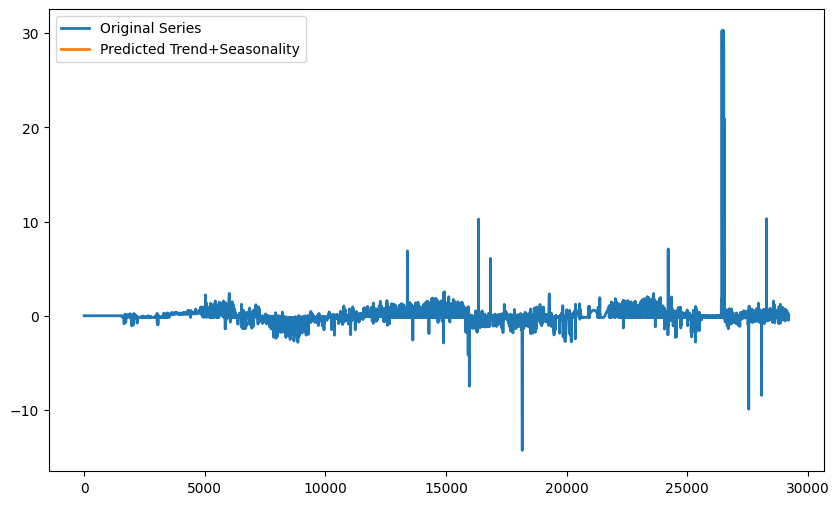

In [83]:
plt.figure(figsize=(10, 6))
plt.plot(test_series[:, :], label='Original Series', linewidth=2)
plt.plot(predicted_trend_seasonality[:, :], label='Predicted Trend+Seasonality', linewidth=2)
plt.legend()
plt.show()

In [61]:
predicted_trend_seasonality = lstm_model.predict(test_series)

1/1 [==============================] - 1s 699ms/step


### LSTM-AE with reconstructed_data as normal

In [58]:
reconstructed_data.index = pd.to_datetime(reconstructed_data['ds'])
reconstructed_data = reconstructed_data.fillna(method = "ffill")

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/1548268338.py:2: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



In [59]:
# orignal data
prof1.index = pd.to_datetime(prof1['ds'])
prof1 = prof1.fillna(method = "ffill")

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/2715252278.py:3: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



In [60]:
### split data
signal_train = reconstructed_data['2020-01-01':'2023-01-31']['y'].values 
signal_valid = reconstructed_data['2023-02-01':'2023-05-01']['y'].values 
signal_test = prof1['2020-01-01':'2023-05-01']['y'].values 

# set window length
window_length = 12 * 2

train_windows = []

for window_start in range(0, len(signal_train) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_train[window_range])
    train_windows.append(window)
    
# shape of training set
x_train = np.array(train_windows)
x_train.shape

valid_windows = []
for window_start in range(0, len(signal_valid) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_valid[window_range])
    valid_windows.append(window)
    
# shape of validation set
x_valid = np.array(valid_windows)
x_valid.shape

test_windows = []

for window_start in range(0, len(signal_test) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_test[window_range])
    test_windows.append(window)

In [79]:
### LSTM Auto-Encoder Model
# optimizer list: adam, adamW, adadelta, adagrad, adamax, nadam

input_length = window_length
input_dim = 1 # number of variable
hidden_dim = 5
batch_size = 64
epochs = 100
opt = keras.optimizers.Adam(learning_rate=0.0005)

def model():
    m = Sequential()
    m.add(LSTM(units=4 * hidden_dim, activation='relu', input_shape=(input_length, input_dim), return_sequences=True))
    m.add(Dropout(rate=0.3))
    m.add(LSTM(units=2 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(LSTM(units=hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.1))
    m.add(LSTM(units=hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.1))
    m.add(LSTM(units=2 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(LSTM(units=4 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(Dense(1))
    return m

# https://gooopy.tistory.com/90
m = model()
m.compile(loss='mse', optimizer=opt) # adam to rmsprop
m.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_6 (LSTM)               (None, 24, 20)            1760      
                                                                 
 dropout_6 (Dropout)         (None, 24, 20)            0         
                                                                 
 lstm_7 (LSTM)               (None, 24, 10)            1240      
                                                                 
 dropout_7 (Dropout)         (None, 24, 10)            0         
                                                                 
 lstm_8 (LSTM)               (None, 24, 5)             320       
                                                                 
 dropout_8 (Dropout)         (None, 24, 5)             0         
                                                                 
 lstm_9 (LSTM)               (None, 24, 5)            

In [80]:
checkpointer = ModelCheckpoint(filepath = "lstm.autoencoder.weights.best.hdf5", verbose = 1, save_best_only = True)
earlystopper = EarlyStopping(monitor = 'val_loss', patience = 10, verbose = 0)
tbCallBack = TensorBoard(log_dir = './lstm.autoencoder.tb.graph', histogram_freq = 0, write_graph = True, write_images = True)

In [81]:
history = m.fit(x_train, x_train, batch_size = batch_size, epochs = epochs, validation_data = (x_valid, x_valid), 
                callbacks = [checkpointer, earlystopper, tbCallBack], verbose = 0).history


Epoch 1: val_loss improved from inf to 0.00350, saving model to lstm.autoencoder.weights.best.hdf5

Epoch 2: val_loss did not improve from 0.00350

Epoch 3: val_loss did not improve from 0.00350

Epoch 4: val_loss did not improve from 0.00350

Epoch 5: val_loss did not improve from 0.00350

Epoch 6: val_loss did not improve from 0.00350

Epoch 7: val_loss did not improve from 0.00350

Epoch 8: val_loss did not improve from 0.00350

Epoch 9: val_loss did not improve from 0.00350

Epoch 10: val_loss did not improve from 0.00350

Epoch 11: val_loss did not improve from 0.00350


In [82]:
pred_x_valid = m.predict(x_valid)

67/67 [==============================] - 1s 5ms/step


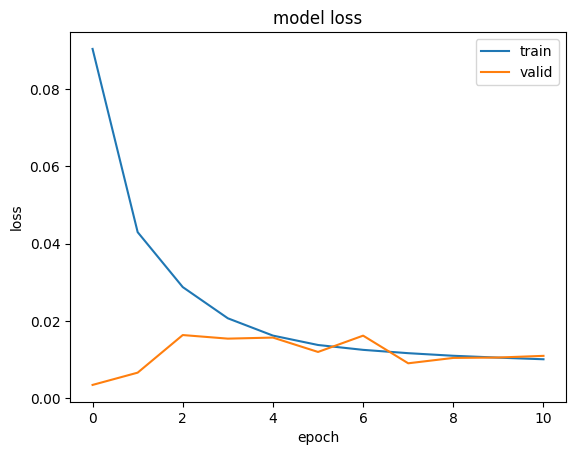

In [83]:
# summarize history for loss
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='best')
plt.show()

In [84]:
x_test = np.array(test_windows)
pred_x_test = m.predict(x_test)

913/913 [==============================] - 5s 5ms/step


In [85]:
# calculate error score
all_errors_valid = pd.Series(np.squeeze((x_valid.shape[:-1]) - pred_x_valid.reshape(pred_x_valid.shape[:-1])[:,:]).flatten())
all_errors_test = pd.Series(np.squeeze((x_test.shape[:-1]) - pred_x_test.reshape(pred_x_test.shape[:-1])[:,:]).flatten())

In [86]:
# calculate error score (window)
def sum_abs_errors_window(errors_in_window):
    return np.sum(np.abs(errors_in_window))

errors_test_per_window = np.squeeze(x_test.shape[:-1] -  pred_x_test.reshape(pred_x_test.shape[:-1])[:,:])
sum_abs_errors_window_0 = np.sum(np.abs(errors_test_per_window[0]))
sum_abs_errors_per_window = pd.Series([sum_abs_errors_window(errors_in_window) for errors_in_window in errors_test_per_window])

In [93]:
# Top anomalous windows ranked and get index
pred_outlier_indices = sum_abs_errors_per_window.nlargest(10).index.values

In [94]:
intervel_length = 1

In [95]:
def highlightComaprison(series, index, colorSTR):
    # Create a mask to identify where the Series values equal 4
    for i in range(len(index)):
        val = series[index[i]]
        mask = ((series) == val) 
        
        # Find the start and end indices of each continuous section where the value equals 4
        section_start = mask & ~mask.shift(fill_value=False)
        section_end = mask & ~mask.shift(-1, fill_value=False)
        
        for start, end in zip(section_start[section_start].index, section_end[section_end].index):
            plt.axvspan(start, end, color=colorSTR, alpha = 0.8)

In [96]:
test = pd.Series(signal_test)
test.index = prof1['2020-01-01':'2023-05-01'].index

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/4180722373.py:4: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



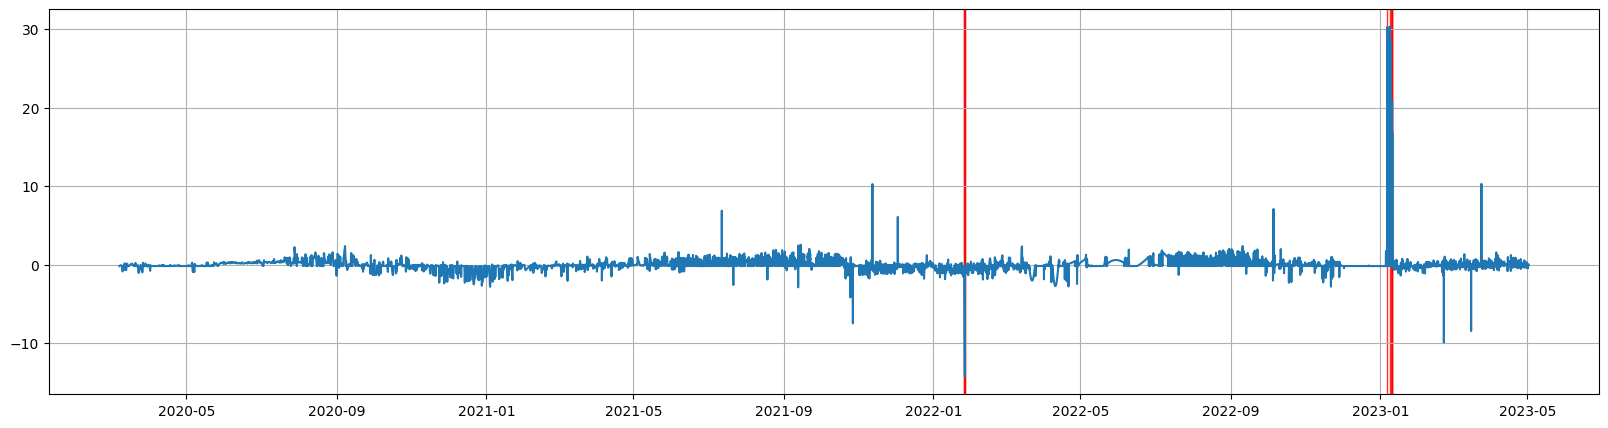

In [97]:
### Visualize anomaly point with test data

plt.figure(figsize = (20, 5))
plt.plot(prof1['2020-01-01':'2023-05-01'].index, test)
highlightComaprison(test, pred_outlier_indices, 'red')
plt.grid(True);

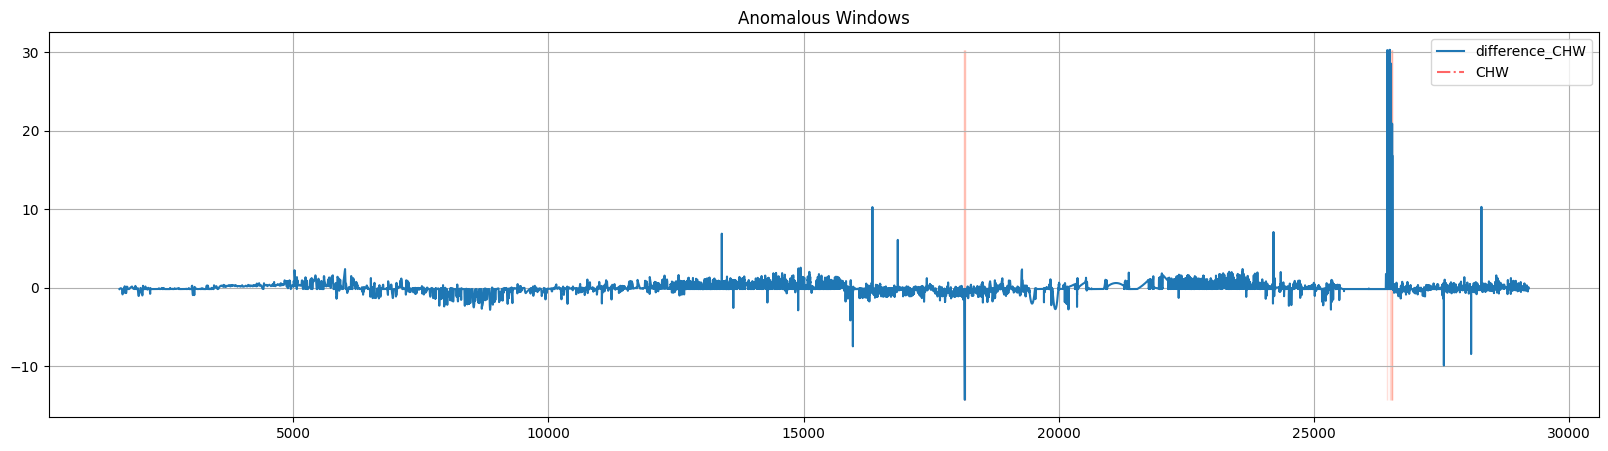

In [98]:
### Visualize anomaly point with test data

plt.figure(figsize = (20, 5))
plt.plot(signal_test)
plt.axhline(y=signal_test.mean(), color='r', linestyle='-.', alpha=0.6) # the  horizontal line for mean
plt.axhline(y=signal_test.mean() + signal_test.std(), color='k', linestyle='--', alpha=0.4) # mean + std_dev
plt.axhline(y=signal_test.mean() + 2 * signal_test.std(), color='k', linestyle=':', alpha=0.4) # mean + 2 * std_dev
plt.axhline(y=signal_test.mean() - 2 * signal_test.std(), color='k', linestyle=':', alpha=0.4) # mean - 2 * std_dev
plt.axhline(y=signal_test.mean() - signal_test.std(), color='k', linestyle='--', alpha=0.4) # mean - std_dev
for w_index in pred_outlier_indices:
    plt.fill_betweenx((np.nanmin(signal_test), np.nanmax(signal_test)), w_index, w_index + intervel_length - 1, alpha=0.2, color='tomato')
plt.title('Anomalous Windows')
plt.legend(["difference_CHW", "CHW"])
plt.grid(True);

In [56]:
### Outlier detection (contain None for spike)

data1 = scaled_df[filtered_columns]["2022-04-01 00:00:00": "2022-12-31 22:00:00"]
data1[data1 < -0.1] = None
data1[data1 > 0.1] = None
data1 = data1.fillna(method = "ffill")
data1 = data1.dropna()

# Numerical dataframe
from sklearn.cluster import DBSCAN
model = DBSCAN(eps = 0.001, min_samples = 10).fit(data1)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_62669/3009463891.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data1 = data1.fillna(method = "ffill")


In [35]:
data1.columns

Index(['b055_raw_group2', 'b103_raw_group2', 'b166_raw_group2',
       'b002_raw_group2', 'b084_raw_group2', 'b081_raw_group2'],
      dtype='object')

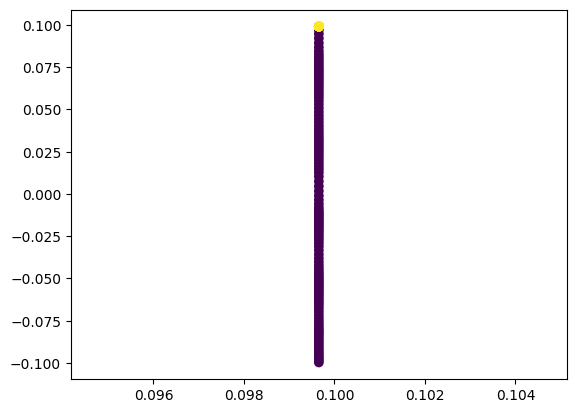

In [38]:
colors = model.labels_
plt.scatter(data1["b084_raw_group2"], data1["b081_raw_group2"], c = colors)

In [39]:
data1[model.labels_ == -1]

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
Date/Time,,,,,,
2022-11-20 19:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.099678
2022-11-20 20:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.098495
2022-11-20 21:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.097326
2022-11-20 22:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.096099
2022-11-20 23:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.094775
...,...,...,...,...,...,...
2022-11-25 13:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.086765
2022-11-25 14:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.089293
2022-11-25 15:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.092072


In [40]:
# GMM 모델 생성
n_clusters = 10  # 클러스터 수를 설정
covariance_type = 'spherical'  # 또는 다른 유형 선택 가능

gmm = GaussianMixture(n_components = n_clusters, covariance_type = covariance_type)
gmm.fit(data1)

# 클러스터 할당
cluster_labels = gmm.predict(data1)

# 결과를 데이터프레임에 추가
data1['Cluster_Label'] = cluster_labels

In [41]:
# Isolation Forest 모델 생성
isolation_forest = IsolationForest(contamination=0.05)  # contamination은 이상치 비율을 나타냅니다

# 모델 훈련
isolation_forest.fit(data1)

# 이상치 여부를 예측 (-1은 이상치, 1은 정상치)
outlier_labels = isolation_forest.predict(data1)

# 결과를 데이터프레임에 추가
data1['Outlier_Label'] = outlier_labels

In [42]:
data1.columns

Index(['b055_raw_group2', 'b103_raw_group2', 'b166_raw_group2',
       'b002_raw_group2', 'b084_raw_group2', 'b081_raw_group2',
       'Cluster_Label', 'Outlier_Label'],
      dtype='object')

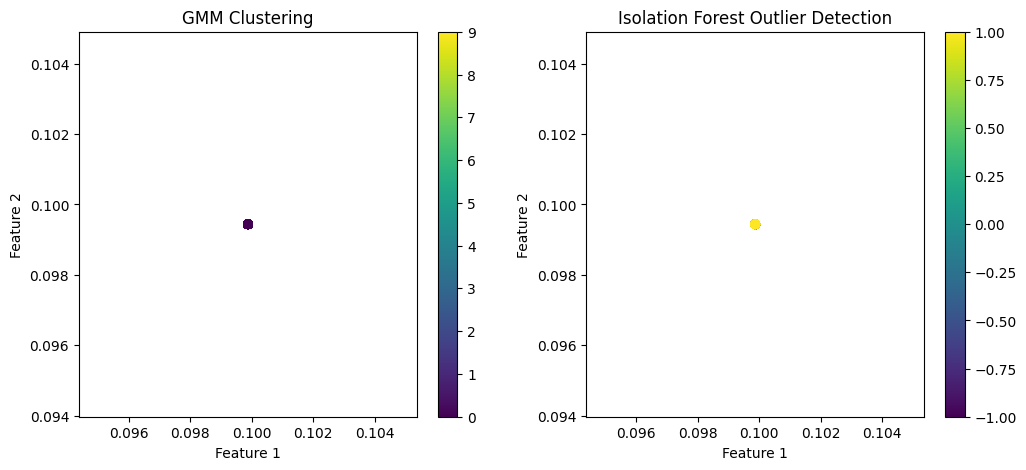

In [44]:
# 클러스터링 결과 및 이상치 시각화
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 클러스터링 결과 시각화
scatter1 = ax1.scatter(data1['b055_raw_group2'], data1['b103_raw_group2'], c=cluster_labels, cmap='viridis')
ax1.set_title("GMM Clustering")
ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Feature 2")
fig.colorbar(scatter1, ax=ax1)

# 이상치 탐지 결과 시각화
scatter2 = ax2.scatter(data1['b055_raw_group2'], data1['b103_raw_group2'], c=outlier_labels, cmap='viridis')
ax2.set_title("Isolation Forest Outlier Detection")
ax2.set_xlabel("Feature 1")
ax2.set_ylabel("Feature 2")
fig.colorbar(scatter2, ax=ax2)

plt.show()

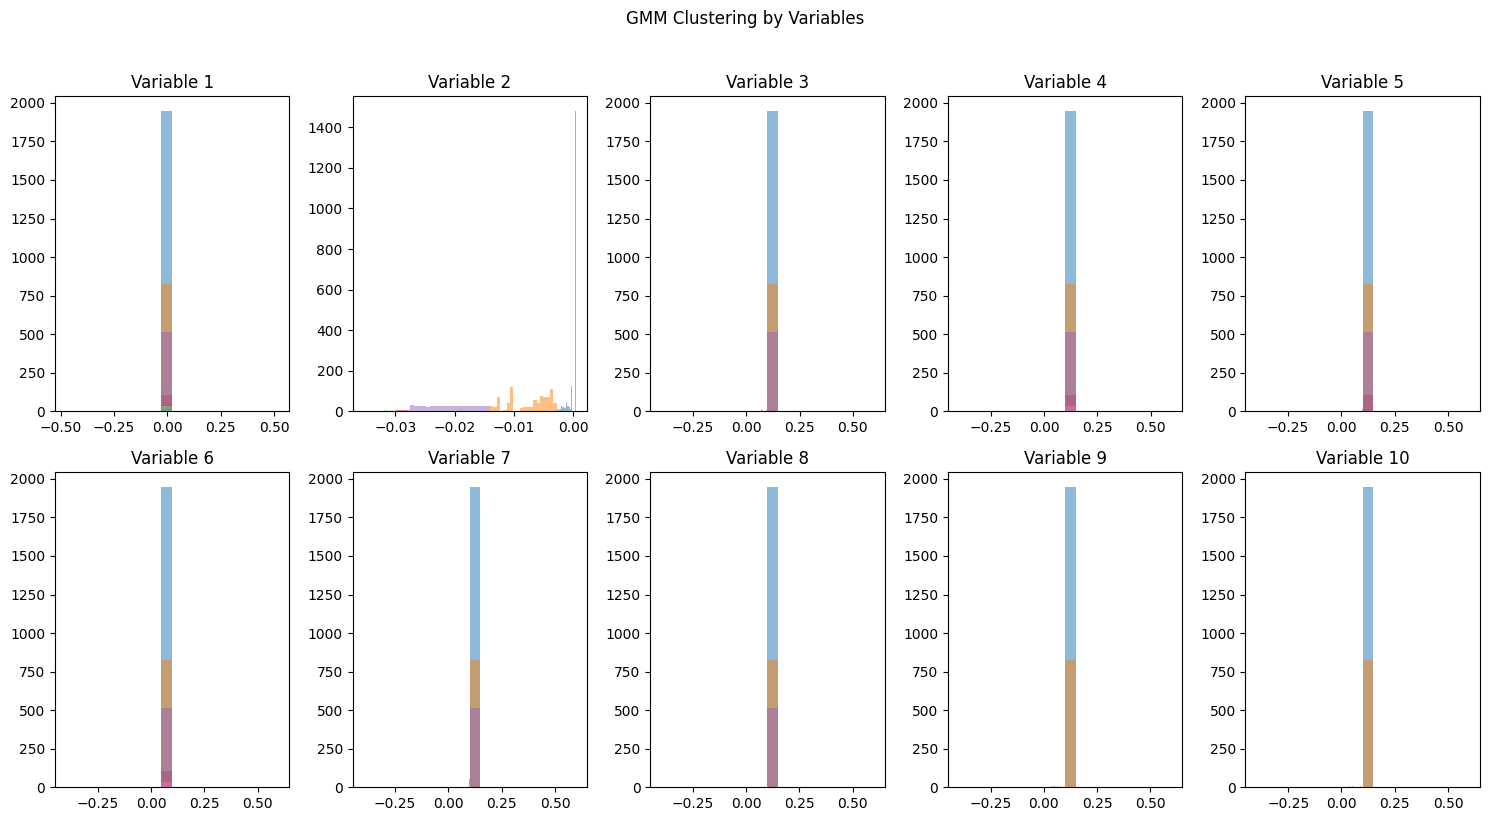

In [103]:
# 클러스터링 결과 시각화
plt.figure(figsize=(15, 8))
for cluster_label in range(n_clusters):
    cluster_data = data1[cluster_labels == cluster_label]
    for i in range(10):  # 10개 변수
        plt.subplot(2, 5, i + 1)
        plt.hist(cluster_data.iloc[:, i], bins = 20, alpha = 0.5, label = f'Cluster {cluster_label + 1}')
        plt.title(f'Variable {i + 1}')
    
plt.suptitle("GMM Clustering by Variables", y = 1.02)
plt.tight_layout()
plt.show()

In [105]:
cluster_data

,b181_raw_group1,b146_raw_group1,b153_raw_group1,b147_raw_group1,b165_raw_group1,b167_raw_group1,b195_raw_group1,b790_raw_group1,b116_raw_group1,b064_raw_group1,Cluster_Label,Outlier_Label
Date/Time,,,,,,,,,,,,
2022-10-11 22:00:00,0.021912,-0.002759,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-11 23:00:00,0.021912,-0.002746,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 00:00:00,0.021912,-0.002732,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 01:00:00,0.021912,-0.002716,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 02:00:00,0.021912,-0.002699,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-31 18:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-12-31 19:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-12-31 20:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1


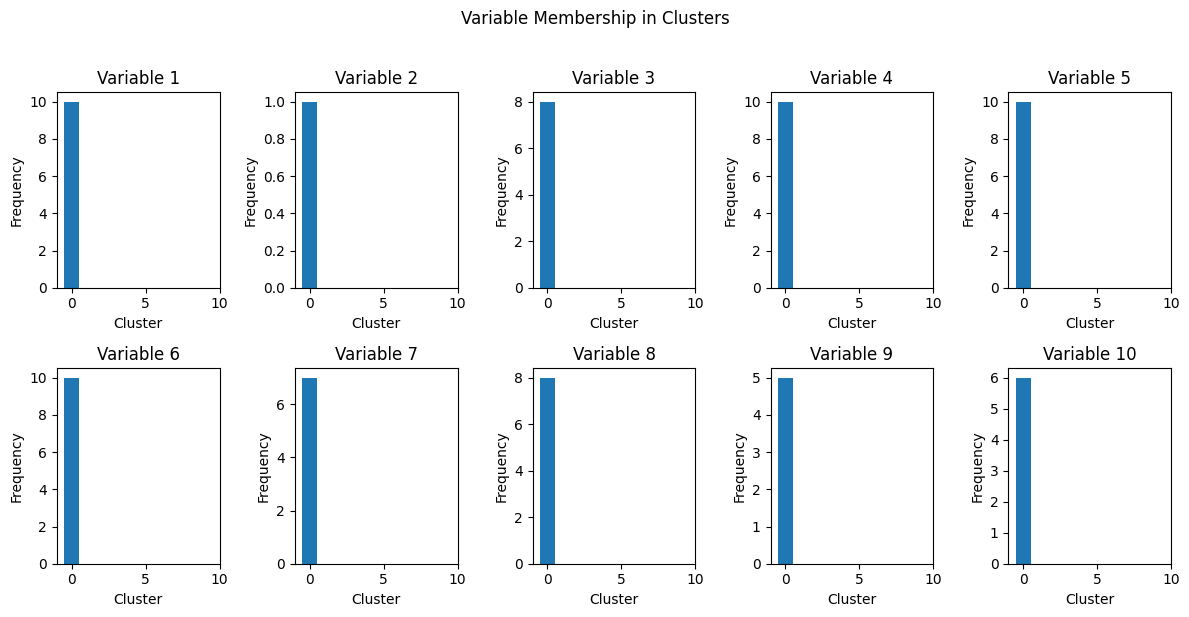

In [107]:
import numpy as np

# 각 변수의 클러스터 소속 확인
variable_cluster_labels = np.zeros((10, n_clusters))  # 변수의 개수 x 클러스터 수
for cluster_label in range(n_clusters):
    cluster_data = data1[cluster_labels == cluster_label]
    cluster_data = cluster_data.drop(['Cluster_Label', "Outlier_Label"], axis = 1)
    variable_cluster_labels[:, cluster_label] = np.mean(cluster_data, axis=0)


# 변수별 클러스터 소속 시각화
plt.figure(figsize=(12, 6))
for i in range(10):  # 10개 변수
    plt.subplot(2, 5, i + 1)
    counts, bins, _ = plt.hist(variable_cluster_labels[i], bins=range(n_clusters + 1), align='left')
    plt.title(f'Variable {i + 1}')
    plt.xlabel('Cluster')
    plt.ylabel('Frequency')
    
plt.suptitle("Variable Membership in Clusters", y=1.02)
plt.tight_layout()
plt.show()


### Generate NAN and Impute GAN (pilot)

In [79]:
data1 = data1.reset_index()
# data1 = data1.drop(['Index'], axis = 1)

In [ ]:
# 결측값 생성

num_points = len(data1)
num_variables = 6
missing_rate = 0.2
for column in df.columns:
    num_missing = int(num_points * missing_rate)
    missing_indices = np.random.choice(num_points, num_missing, replace=False)
    data1.loc[missing_indices, column] = np.nan

In [87]:
data1.index = data1["Date/Time"]
data1 = data1.drop(['Date/Time', "index"], axis = 1)

# Extract data with pt
filtered_columns = [col for col in data1.columns if "raw" in col]

# 선택한 변수를 새로운 데이터 프레임으로 추출
data1 = data1[filtered_columns]["2022-04-01 00:00:00": "2022-12-31 22:00:00"]

In [111]:
from tensorflow import keras
import torch
import torch.nn as nn
import torch.optim as optim

In [88]:
data1.head()

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
Date/Time,,,,,,
2022-04-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
2022-04-01 01:00:00,NaN,0.000047,0.000284,0.000306,0.000469,NaN
2022-04-01 02:00:00,0.0,0.000058,0.000281,NaN,NaN,NaN
2022-04-01 03:00:00,0.0,0.000035,0.000268,0.000308,NaN,NaN
2022-04-01 04:00:00,0.0,NaN,NaN,0.000298,NaN,NaN


In [91]:
data1 = data1.reset_index()
data1 = data1.drop(['Date/Time'], axis = 1)

In [93]:
data1

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,0.000047,0.000284,0.000306,0.000469,NaN
2,0.0,0.000058,0.000281,NaN,NaN,NaN
3,0.0,0.000035,0.000268,0.000308,NaN,NaN
4,0.0,NaN,NaN,0.000298,NaN,NaN
...,...,...,...,...,...,...
6594,0.0,0.000035,0.000287,NaN,0.000000,0.000426
6595,0.0,NaN,NaN,0.000286,NaN,NaN
6596,0.0,NaN,0.000265,0.000288,0.000012,0.000416
6597,NaN,NaN,0.000216,NaN,0.000000,0.000435


In [116]:
# 데이터프레임을 PyTorch 텐서로 변환
real_data = torch.FloatTensor(data1.dropna().values)

In [122]:
# Generator 모델 정의
class Generator(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(Generator, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Linear(128, output_dim),
            nn.Tanh()
        )

    def forward(self, x):
        return self.fc(x)

# Discriminator 모델 정의
class Discriminator(nn.Module):
    def __init__(self, input_dim):
        super(Discriminator, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.fc(x)

In [128]:
# Generator와 Discriminator 모델 초기화
input_dim = 32
output_dim = num_variables
generator = Generator(input_dim, output_dim)
discriminator = Discriminator(output_dim)

# 손실 함수 및 옵티마이저 정의
criterion = nn.BCELoss()
optimizer_g = optim.Adam(generator.parameters(), lr=0.0002)
optimizer_d = optim.Adam(discriminator.parameters(), lr=0.0002)

In [134]:
# GAN 모델 훈련
num_epochs = 100
batch_size = 32

for epoch in range(num_epochs):
    num_batches = real_data.shape[0] // batch_size
    for _ in range(num_batches):
        noise = torch.randn(batch_size, input_dim)
        generated_data = generator(noise)
        real_labels = torch.ones((batch_size, 1), dtype=torch.float32)
        fake_labels = torch.zeros((batch_size, 1), dtype=torch.float32)

        # Discriminator 훈련
        optimizer_d.zero_grad()
        real_output = discriminator(real_data[:batch_size])
        fake_output = discriminator(generated_data)
        discriminator_loss_real = criterion(real_output, real_labels)
        discriminator_loss_fake = criterion(fake_output, fake_labels)
        discriminator_loss = discriminator_loss_real + discriminator_loss_fake
        discriminator_loss.backward(retain_graph=True)
        optimizer_d.step()

        # Generator를 통한 GAN 훈련
        optimizer_g.zero_grad()
        gan_labels = torch.ones((batch_size, 1), dtype=torch.float32)
        gan_output = discriminator(generated_data)
        gan_loss = criterion(gan_output, gan_labels)
        gan_loss.backward()
        optimizer_g.step()

    print(f'Epoch {epoch}, D Loss: {discriminator_loss.item()}, G Loss: {gan_loss.item()}')


Epoch 0, D Loss: 1.3854780197143555, G Loss: 0.6327202320098877
Epoch 1, D Loss: 1.3908488750457764, G Loss: 0.6290866136550903
Epoch 2, D Loss: 1.3863091468811035, G Loss: 0.6368914246559143
Epoch 3, D Loss: 1.3897672891616821, G Loss: 0.6354539394378662
Epoch 4, D Loss: 1.3817918300628662, G Loss: 0.6448863744735718
Epoch 5, D Loss: 1.3989853858947754, G Loss: 0.6333292722702026
Epoch 6, D Loss: 1.372666358947754, G Loss: 0.6603043675422668
Epoch 7, D Loss: 1.3731648921966553, G Loss: 0.6610397100448608
Epoch 8, D Loss: 1.3767998218536377, G Loss: 0.6590506434440613
Epoch 9, D Loss: 1.3822531700134277, G Loss: 0.6567761898040771
Epoch 10, D Loss: 1.379887342453003, G Loss: 0.6593412160873413
Epoch 11, D Loss: 1.3736572265625, G Loss: 0.6676796078681946
Epoch 12, D Loss: 1.3731087446212769, G Loss: 0.6703320145606995
Epoch 13, D Loss: 1.3778290748596191, G Loss: 0.6668186783790588
Epoch 14, D Loss: 1.3695826530456543, G Loss: 0.6758610606193542
Epoch 15, D Loss: 1.371976613998413, G L

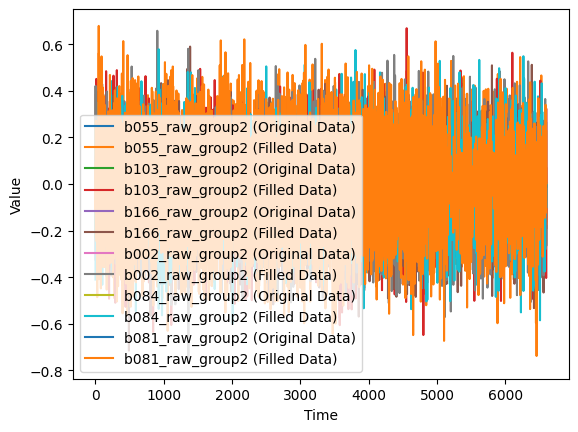

In [136]:
# 결측값을 GAN을 사용하여 채우기
missing_data = data1.copy()
for column in missing_data.columns:
    missing_indices = missing_data[column].isna()
    num_missing = missing_indices.sum()
    noise = torch.randn(num_missing, input_dim)
    generated_values = generator(noise).detach().numpy()
    missing_data.loc[missing_indices, column] = generated_values.flatten()[:num_missing]

# 결과를 시각화
for column in data1.columns:
    plt.plot(data1[column], label=f'{column} (Original Data)')
    plt.plot(missing_data[column], label=f'{column} (Filled Data)')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

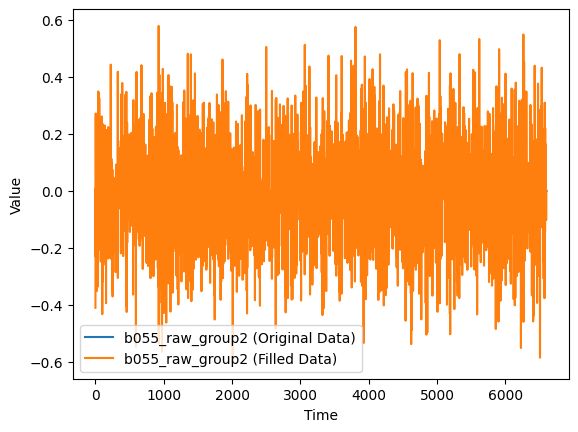

In [148]:
# 결과를 시각화

plt.plot(data1["b084_raw_group2"], label=f'{column} (Original Data)')
plt.plot(missing_data["b084_raw_group2"], label=f'{column} (Filled Data)')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

ValueError: x and y must be the same size

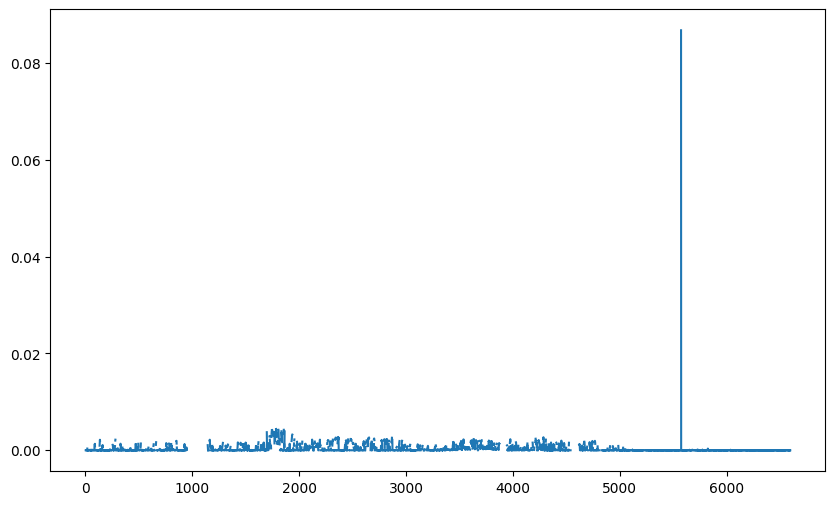

In [141]:
# 결과를 시각화
for column in data1.columns:
    plt.figure(figsize=(10, 6))
    plt.plot(data1[column], label=f'{column} (Original Data)')
    
    # 결측값인 지점에 동그라미 표시
    missing_indices = data1[column].isna()
    plt.scatter(missing_indices.index, data1[column][missing_indices], c='r', marker='o', label='Missing Data')
    
    plt.plot(missing_data[column], label=f'{column} (Filled Data)')
    
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.show()